# 再現ノートブック：AI対戦相手の難易度と再訪

## 概要

### 問い

Lichess では、プレイヤーは対戦するチェスAI（「ボット」）を自分で選ぶ。自分よりずっと強いボットもあれば、ずっと弱いボットもある。
ボットの難しさによって、プレイヤーがそのボットとまた対戦するかどうかは変わるのか。

### 答えの要点

- ボットの強さが自分と互角に近いとき、プレイヤーは最もよく戻ってくる。ボットがずっと強くても、ずっと弱くても、戻る確率は下がる（逆U字）。
- 互角から同じだけ離れたとき、ボットが強すぎる場合の方が、弱すぎる場合より戻る確率が下がる。
- ただし、同じプレイヤーと同じボットの組の中で比べると、この左右の違いははっきりしない。

### このノートブックの役割

- 論文「AI対戦相手の難易度と再訪：オンラインチェス内のプレイヤー再訪行動の縦断的分析」（Ito, 2026）の数値と図を、[Lichess_BotDataCollection](https://github.com/konbraphat51/Lichess_BotDataCollection) が Lichess のオープンデータベース（2022年8月〜2026年8月のレーティング戦）から作った表をもとに再計算する。
- 最後に、再計算した数値を論文に記載した数値と一つずつ照合する。

### 主張の正確な内容

- 比べ方：各プレイヤーを、そのプレイヤー自身とだけ比較する。
- 逆U字（段階2）：セッション後7日以内に同じボットとまた対戦する確率は、期待スコアについて逆U字になる。判定は2直線の検定による（2.4）。
- 左右差（段階3）：両端の低下は難しい側の方が大きい（3.1）。互角から同じだけ離れたとき、難しい側の再訪の方が平均で約1.5ポイント低い（3.2）。ただし同じプレイヤーと同じボットの組の中では、はっきりしない。
- 測らないもの：頂上の位置と幅は、このノートブックでは測らない。
- 理論との関係：フロー理論は、挑戦が技能に釣り合うときに体験が最も良くなると予測する（Csikszentmihalyi, 1990）。ただし本研究が測っているのは再訪であり、楽しさではない。

### 論文との対応

| 論文 | ノートブック | 出力 |
|---|---|---|
| 3節 データ（抽出条件、対局数、プレイヤー数、ボット数） | 段階1、2.1 | `summary["panel"]["describe"]` |
| 4.1節 再訪、期待スコア、線形確率モデル（式1） | 全体で使う用語、2.2 | — |
| 4.1節 9つのモデル（Base、PairFE、AnyBot × 7・28・91日） | 2.3 | `results/panel_horizons.csv` |
| 4.1節 Two-lines検定、表1 | 2.4（2直線の検定） | `results/panel_two_lines.csv` |
| 図1 生の7日再訪率 | 2.4 | `results/figures/d1_return_raw.png` |
| 5.1節 Binscatter（式2） | 3.1 | `results/shape_flexible.csv` |
| 図2 Binscatter（期間と比べ方の比較） | 3.1 | `results/figures/d1_binscatter_models.png` |
| 5.1節 鏡像差の検定（式3）、表2 | 3.2 | `results/shape_mirror.csv`、`results/shape_mirror_pairs.csv` |
| 図3 互角を軸に折り返した比較 | 3.2 | `results/figures/d1_mirror.png` |
| 論文に記載した数値の照合 | 段階4 | `results/comparison.csv` |

論文の Two-lines検定は、このノートブックの「2直線の検定」と同じものである。モデルの名前（Base7 など）は2.3で定める。

### 各段階の構成

各段階は次の順に示す。

1. その段階の問い（段階2・3の問いには、段階の番号と記号で Q2a〜Q2e、Q3b の番号を付ける。番号はノートブック全体で1つの問いだけを指す）
2. 計算の内容（必要に応じて、データの行の例と計算例を添える）
3. コードと出力
4. 出力の読み方

### 分析のコードの置き場所

分析のコードはすべてこのノートブック内にある。どの数値もここで確認できるようにするためである。

- 各関数は、初めて使う直前で定義する。
- 可能な場合は、定義の直後に、答えが分かっている小さな人工データで関数を検査する（`checks passed` で終わるセル）。
- パッケージ `lichess_d1` に置いているのは、データの場所と図の体裁だけである。
- 参考文献は最後にまとめた。

## 全体で使う用語

| 用語 | 意味 |
|---|---|
| **期待スコア（es）** | そのプレイヤーにとってボットがどれだけ易しいかを、双方のレーティングから Elo の式（Elo, 1978）で表した値である：`es = 1 / (1 + 10^((ボットのレーティング − プレイヤーのレーティング) / 400))`。0.5 が互角である。0.75 はプレイヤーが4点中3点を取る見込みで、ボットが約190点弱い。0.25 ならボットが約190点強い。Lichess のレーティングは Glicko-2 による（Glickman, 2022）。 |
| **セッション** | 1体のボットとの、対局間隔が30分を超えずに続く一連の対局である。1局だけのこともあれば、何局も含むこともある。分析では1セッションを1行（その最後の対局）として扱う。その対局の期待スコアをセッションの es とし、再訪もその対局から数える。 |
| **7日再訪** | セッションの最後の対局の30分後から7日後までに同じボットとまた対戦すれば1、しなければ0とする。7日後がデータの終わりを越える場合は欠測とする。 |
| **プレイヤー内** | 各プレイヤーを、そのプレイヤー自身とだけ比較する。モデルは各プレイヤー自身の平均的な再訪率を取り除く（プレイヤー固定効果、within推定量；Wooldridge, 2010, 10章）。このため、もともとよく戻ってくる人がいるというだけでは結果が生じない。 |
| **ペア内** | さらに厳しい比較である。同じプレイヤー*と*同じボットの組を、その組自身と比較する（プレイヤーから見たボットの強さは時間とともに変わる）。 |
| **線形確率モデル（LPM）** | 結果が0か1の線形回帰である。各係数がそのまま確率の変化を表す（Wooldridge, 2010, 15章；Angrist & Pischke, 2009）。同じプレイヤーのセッションは互いに独立でないため、標準誤差はプレイヤー単位のクラスター頑健標準誤差とする（Cameron & Miller, 2015）。 |
| **es と es² の項** | モデルは 再訪 = a + b·es + c·es² +（統制変数）を当てはめる。c（es² の項、2次の項）が負なら上に凸、すなわち逆U字である。c が負に大きいほど山は鋭い。頂上から0.3離れると、再訪はおよそ c × 0.3² だけ低下する（c = −0.3 なら約2.7パーセントポイント）。 |
| **頂点** | 山の頂上 es = −b / (2c) である。95%区間はデルタ法で求める（Oehlert, 1992）。 |

## 0. 準備

### この段階の内容

- ライブラリを読み込み、研究の期間（49か月）を固定する。
- データの場所をノートブックに伝える。
- 49か月分のデータと4年分のパネルがそろっているかを確かめる。

### 環境変数

Jupyter を起動する前に、次を設定する（括弧内は既定値）。

- `D1_DATA_ROOT`：Lichess_BotDataCollection のデータのフォルダ（`<repo>/data`）
- `D1_INTERIM_DIR`：月ごとのフォルダと `census-panel`（`<D1_DATA_ROOT>/interim`）
- `D1_BOT_ACCOUNTS`：ボットのアカウントの一覧 `bot_accounts.parquet`（`<D1_DATA_ROOT>/external/bot_accounts.parquet`）
- `D1_RESULTS_DIR`：表、図、保存したモデルの推定結果の出力先（`<repo>/results`）
- `D1_REFRESH`：`1` にすると、保存済みの結果を読まず、すべてのモデルを推定し直す

### 保存した推定結果

- モデルの推定結果は、計算した直後に `results/cache/` に保存され、次回からはそれを読み込む（下の関数 `cached()`）。
- すべて推定し直すと、月ごとの分析に約10分、パネルに10〜30分と数GBのメモリを要する。

### 出力の読み方

- `missing: none` と `panel present: True` が出ていれば、必要なデータはすべてそろっている。
- 後で別の実行と比較できるように、パッケージのバージョンも表示する。

In [1]:
import json
import math
import os
import re
from collections.abc import Callable, Iterator
from dataclasses import dataclass
from functools import cache
from importlib.metadata import version
from typing import Any

import numpy as np
import pandas as pd
import patsy
import polars as pl
import statsmodels.api as sm
from IPython.display import Image, Markdown, display
from matplotlib.axes import Axes
from scipy import optimize, stats

from lichess_d1 import config
from lichess_d1.plotting import NEUTRAL, SERIES, new_figure, save_figure

pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_cols(20)

# study period (2026-09 is held out for a pre-registered test)
FIRST_MONTH, LAST_MONTH = "2022-08", "2026-08"


def month_range(first: str, last: str) -> Iterator[str]:
    """Yields YYYY-MM months from first to last inclusive."""
    year, month = (int(p) for p in first.split("-"))
    while f"{year:04d}-{month:02d}" <= last:
        yield f"{year:04d}-{month:02d}"
        year, month = (year + 1, 1) if month == 12 else (year, month + 1)


STUDY_MONTHS = tuple(month_range(FIRST_MONTH, LAST_MONTH))

REFRESH = os.environ.get("D1_REFRESH") == "1"
CACHE_DIR = config.RESULTS_DIR / "cache"
FIGURE_DIR = config.RESULTS_DIR / "figures"


def json_default(value: object) -> object:
    """Turns numpy scalars into Python numbers for JSON."""
    return value.item() if hasattr(value, "item") else str(value)


def cached(name: str, compute: Callable[[], Any]) -> Any:
    """The saved result `name` from results/cache; computed and saved first when missing."""
    path = CACHE_DIR / f"{name}.json"
    if REFRESH or not path.exists():
        CACHE_DIR.mkdir(parents=True, exist_ok=True)
        path.write_text(json.dumps(compute(), default=json_default), encoding="utf-8")
    # read back in both cases, so that fresh and saved results are the same Python objects
    return json.loads(path.read_text(encoding="utf-8"))


assert len(STUDY_MONTHS) == 49
print("checks passed")

checks passed


In [2]:
print("interim folder:", config.INTERIM_DIR)
print("bot accounts:  ", config.BOT_ACCOUNTS_PATH)
print("results:       ", config.RESULTS_DIR, "| refit everything:", REFRESH)
missing = [m for m in STUDY_MONTHS if not (config.month_dir(m) / "player_games.parquet").exists()]
print("study months:", len(STUDY_MONTHS), "| missing:", missing or "none")
print("panel present:", (config.month_dir(config.PANEL_NAME) / "player_games.parquet").exists())
for package in ("polars", "pandas", "numpy", "statsmodels", "scipy", "patsy"):
    print(f"{package} {version(package)}")

interim folder: D:\Research\LichessAiPref\interim
bot accounts:   C:\Storage\Research\LichessAiPref\data\external\bot_accounts.parquet
results:        C:\Storage\Research\LichessAiPref\Individuals\Lichess_D1\results | refit everything: False
study months: 49 | missing: none
panel present: True
polars 1.44.2
pandas 3.0.6
numpy 2.5.3
statsmodels 0.15.0
scipy 1.18.1
patsy 1.0.3


## 1. データの中身と、使う対局

### 問い

- データの1行には何が入っているか。
- どの対局を分析に含めるか。
- 期待スコア、セッション、再訪は、行からどう読み取れるか。

### データ

- 月ごとに表 `player_games.parquet` が1つある。1行が**人間とボットの1局**に当たる。
- 列名は人間の側から付けてある。`player` が人間、`opponent` がボット、`player_score` が人間の結果である。

次のセルは、分析で読む列（月ごとの表と、段階2・3で使う4年分のパネルの表）を挙げ、例として1か月分（2024年12月）を読み込む。

In [3]:
MONTH_COLUMNS = (
    "game_id", "player", "opponent", "start", "speed", "is_tournament", "player_elo",
    "opponent_elo", "player_score", "expected_score", "outcome", "session_last",
    "session_length", "return_7d", "pair_game_index",
)
PANEL_COLUMNS = (
    *MONTH_COLUMNS, "month", "end", "n_plies", "player_session_last", "return_28d",
    "return_91d", "any_return_7d", "any_return_28d", "any_return_91d",
)

EXAMPLE_MONTH = "2024-12"
raw = pl.read_parquet(
    config.month_dir(EXAMPLE_MONTH) / "player_games.parquet", columns=list(MONTH_COLUMNS)
)
print(f"{EXAMPLE_MONTH}: {raw.height:,} games in player_games.parquet")
pl.DataFrame({"column": raw.columns, "type": [str(t) for t in raw.dtypes]})

2024-12: 44,692 games in player_games.parquet


column,type
str,str
"""game_id""","""String"""
"""player""","""String"""
"""opponent""","""String"""
"""start""","""Datetime(time_unit='us', time_…"
"""speed""","""String"""
"""is_tournament""","""Boolean"""
"""player_elo""","""Int64"""
"""opponent_elo""","""Int64"""
"""player_score""","""Float64"""


### 残す対局

次をすべて満たす対局だけを分析に含める。
下のコードでは、各条件が `removal_rules()` の1行に対応しており、どの条件にも当てはまらない対局を残す。

- 「人間」がボットでないこと。人間かどうかを直接確認してはおらず、既知のボットでないアカウントを人間とみなす。判定は2段階である。
  1. 称号による判定：Lichess はボットのアカウントに `BOT` という称号を付けており、ダンプの各対局には双方の称号が記録されている。片方だけにこの称号がある対局をデータに含める。
  2. 一覧による判定：2023年12月〜2024年9月のダンプでは、多くのボットに称号が付いていない。そのため、ボット同士の対局が人間対ボットの対局に見えることがある。こうしたアカウントは一覧 `bot_accounts.parquet` で除く。
     - 一覧に入るのは、いずれかの月に `BOT` 称号付きで現れたアカウントと、称号なしで1か月に10体以上の別々のボットと対戦し、Lichess API で取得したプロフィールに称号があったアカウントである。
     - これらのダンプでは名前の大文字小文字も不揃いなので、名前は小文字の ID で照合する。
     - この期間以外の月では、この条件で除かれる対局が1局もないこともある。

  この判定では、次の2つを見逃す。

  - 通常のアカウントで、裏でエンジンを使う人
  - 1か月の対戦ボットが10体未満の、称号のないボット
- リアルタイムの対局（ブレット、ブリッツ、ラピッド、クラシカル）であること。通信戦は1局に何日もかかるため、セッションが定義できない。
- 大会の対局でないこと。大会では相手をプレイヤーが選べない。
- 双方のレーティングと結果が分かること。

続いて `add_derived()` が、モデルで使う変数を加える。

- `es`：期待スコア
- `player_elo_c`：レーティングを (レーティング − 1500) / 100 にしたもの
- `log_pair_idx`：1 + このボットとそれまでに対戦した局数、の対数

In [4]:
ANALYSIS_SPEEDS = ("bullet", "blitz", "rapid", "classical")


def removal_rules(bots: set[str]) -> dict[str, pl.Expr]:
    """Each rule that removes a game from the analysis (a game is kept when none applies)."""
    return {
        "the 'human' is a known bot account": pl.col("player").str.to_lowercase().is_in(bots),
        "not a real-time game (e.g. correspondence)": ~pl.col("speed").is_in(ANALYSIS_SPEEDS),
        "tournament game": pl.col("is_tournament"),
        "a rating is missing": pl.col("player_elo").is_null() | pl.col("opponent_elo").is_null(),
        "the result is missing": pl.col("player_score").is_null(),
    }


def analysis_filter(table: pl.DataFrame, bots: set[str]) -> pl.DataFrame:
    """The games no removal rule applies to."""
    return table.filter(~pl.any_horizontal(*removal_rules(bots).values()))


def add_derived(games: pl.DataFrame) -> pl.DataFrame:
    """Adds the model variables es, player_elo_c and log_pair_idx."""
    return games.with_columns(
        pl.col("expected_score").alias("es"),
        ((pl.col("player_elo") - 1500) / 100).alias("player_elo_c"),
        (pl.col("pair_game_index") + 1).log().alias("log_pair_idx"),
    )


def load_bot_accounts() -> set[str]:
    """Lowercase ids of known bot accounts, including those shown without the BOT title."""
    path = config.BOT_ACCOUNTS_PATH
    if not path.exists():
        raise FileNotFoundError(f"{path} is missing; without it untitled bots count as humans")
    return set(pl.read_parquet(path, columns=["user"])["user"].to_list())


def load_games(folder: Any, columns: tuple[str, ...], bots: set[str]) -> pl.DataFrame:
    """The analysis sample of one month's (or the panel's) player_games.parquet."""
    table = pl.read_parquet(folder / "player_games.parquet", columns=list(columns))
    return add_derived(analysis_filter(table, bots))


def load_month(month: str, bots: set[str]) -> pl.DataFrame:
    """The analysis sample of one study month."""
    return load_games(config.month_dir(month), MONTH_COLUMNS, bots)


# checks on made-up rows: only "alice" passes every rule
made_up = pl.DataFrame({
    "player": ["ToromBot", "alice", "bob", "carol", "dave"],
    "speed": ["blitz", "blitz", "correspondence", "rapid", "bullet"],
    "is_tournament": [False, False, False, True, False],
    "player_elo": [1500, 1500, 1500, 1500, None],
    "opponent_elo": [1500] * 5,
    "player_score": [1.0] * 5,
})
assert analysis_filter(made_up, {"torombot"})["player"].to_list() == ["alice"]
derived = add_derived(pl.DataFrame({
    "expected_score": [0.05, 0.55], "player_elo": [1200, 1700], "pair_game_index": [0, 9],
}))
assert derived["player_elo_c"].to_list() == [-3.0, 2.0]
assert math.isclose(derived["log_pair_idx"][1], math.log(10))
print("checks passed")

checks passed


次のセルは、例の月にこれらの条件を適用する。表は、各条件で除かれる対局数を示す（1局が複数の条件に当てはまることもある）。

In [5]:
bots = load_bot_accounts()
display(pl.DataFrame({
    "reason for removal": list(removal_rules(bots)),
    "games removed": [raw.filter(rule).height for rule in removal_rules(bots).values()],
}))
games = add_derived(analysis_filter(raw, bots))
print(f"kept {games.height:,} of {raw.height:,} games ({100 * games.height / raw.height:.1f}%)")

reason for removal,games removed
str,i64
"""the 'human' is a known bot acc…",0
"""not a real-time game (e.g. cor…",146
"""tournament game""",0
"""a rating is missing""",0
"""the result is missing""",66


kept 44,544 of 44,692 games (99.7%)


### 1人の人間と1体のボット

次のセルは、例の月にある人間が1体のボットと対戦したすべての対局を示す。

- この組は、決まった規則（4〜6局、2つのセッション、1回の再訪、ほぼ互角の対局）で選んでおり、この段階の考え方が数行で見渡せるようにしてある。
- 人間の名前は `player_A` に置き換えた。ボットは公開アカウントなので名前をそのまま示す。

In [6]:
# the example: one player-bot pair with 4-6 games, two sessions, one return, near-even games
pairs = games.group_by("player", "opponent").agg(
    pl.len().alias("games"),
    pl.col("session_last").sum().alias("sessions"),
    pl.col("return_7d").sum().alias("returns"),
    pl.col("es").mean().alias("mean_es"),
)
example = (
    pairs.filter(
        pl.col("games").is_between(4, 6)
        & (pl.col("sessions") == 2)
        & (pl.col("returns") == 1)
        & pl.col("mean_es").is_between(0.35, 0.65)
    )
    .sort("player", "opponent")
    .row(0, named=True)
)
SHOWN = [
    "start", "player", "opponent", "speed", "player_elo", "opponent_elo", "player_score",
    "expected_score", "session_length", "session_last", "return_7d", "pair_game_index",
]


def example_rows(table: pl.DataFrame, columns: list[str] = SHOWN) -> pl.DataFrame:
    """The example pair's games in time order, with the player's name replaced."""
    is_pair = (pl.col("player") == example["player"]) & (pl.col("opponent") == example["opponent"])
    return (
        table.filter(is_pair)
        .sort("start")
        .with_columns(pl.lit("player_A").alias("player"))
        .select(columns)
    )


example_rows(raw)

start,player,opponent,speed,player_elo,opponent_elo,player_score,expected_score,session_length,session_last,return_7d,pair_game_index
"datetime[μs, UTC]",str,str,str,i64,i64,f64,f64,u32,bool,bool,i64
2024-12-01 15:26:23 UTC,"""player_A""","""sargon-2ply""","""rapid""",1422,1335,0.0,0.62265,3,false,false,0
2024-12-01 15:28:41 UTC,"""player_A""","""sargon-2ply""","""rapid""",1400,1341,1.0,0.584101,3,false,false,1
2024-12-01 15:36:07 UTC,"""player_A""","""sargon-2ply""","""rapid""",1414,1337,1.0,0.609033,3,true,true,2
2024-12-03 12:39:15 UTC,"""player_A""","""sargon-2ply""","""rapid""",1395,1325,0.5,0.599397,2,false,false,3
2024-12-03 12:43:18 UTC,"""player_A""","""sargon-2ply""","""rapid""",1393,1326,1.0,0.595243,2,true,false,4


### 列の意味

| 列 | 意味 |
|---|---|
| `start` | 対局の開始時刻（UTC） |
| `player`、`opponent` | 人間とボット |
| `speed` | 持ち時間の種類：ブレット、ブリッツ、ラピッド、クラシカル（または通信戦） |
| `player_elo`、`opponent_elo` | 対局前の双方の Lichess レーティング |
| `player_score` | 人間の結果：1 = 勝ち、0.5 = 引き分け、0 = 負け |
| `expected_score` | 人間にとってボットがどれだけ易しいか（Elo の式。下を参照） |
| `session_length` | その対局が属するセッションの対局数 |
| `session_last` | セッションの最後の対局なら true |
| `return_7d` | セッションの最後の対局の30分後から7日後までに、このボットとまた対戦したか。7日後がデータの終わりを越える場合は欠測。ほかの対局では意味をもたない。 |
| `pair_game_index` | この人間がこのボットとそれまでに対戦した局数（0 = 初めて） |

### 例の読み方

- 1つ目のセッション：12月1日に `player_A` はボット `sargon-2ply` とラピッドを10分以内に3局指した（`session_length` = 3）。
  - ボットは約80点弱いので、`expected_score` は約0.6（やや易しい）になる。
  - 3局目でセッションが終わり（`session_last` = true）、2日後にまた対戦したので `return_7d` = true になる。
- 2つ目のセッション：12月3日の2局である。その後7日以内にはこのボットと対戦しなかったので、その `return_7d` は false である。
- 分析では、1セッションが1行（その最後の対局）になる。

### 期待スコアの計算例

`expected_score` は Elo の式（Elo, 1978）から求める。

- 最初の表：レーティング1500のプレイヤーが、400点弱いボットから400点強いボットまでと対戦するときの値。
- 2つ目の表：同じ式を例の行に当てはめ、データに入っている値と一致することを示す。

In [7]:
def elo_expected_score(player_rating: pl.Expr, bot_rating: pl.Expr) -> pl.Expr:
    """Elo's expected score of the player against the bot."""
    return 1 / (1 + 10 ** ((bot_rating - player_rating) / 400))


display(
    pl.DataFrame({"player rating": [1500] * 5, "bot rating": [1100, 1300, 1500, 1700, 1900]})
    .with_columns(expected_score=elo_expected_score(pl.col("player rating"), pl.col("bot rating")))
)
example_rows(games, ["player_elo", "opponent_elo", "expected_score"]).with_columns(
    recomputed=elo_expected_score(pl.col("player_elo"), pl.col("opponent_elo"))
)

player rating,bot rating,expected_score
i64,i64,f64
1500,1100,0.909091
1500,1300,0.759747
1500,1500,0.5
1500,1700,0.240253
1500,1900,0.090909


player_elo,opponent_elo,expected_score,recomputed
i64,i64,f64,f64
1422,1335,0.62265,0.62265
1400,1341,0.584101,0.584101
1414,1337,0.609033,0.609033
1395,1325,0.599397,0.599397
1393,1326,0.595243,0.595243


## 2. 逆U字の検定

### 問いと進め方

問いは次の5つである。

- Q2a：期待スコアと7日以内の再訪の関係は、山の形（逆U字）か。つまり、互角の付近で最も高く、難しい側でも易しい側でも下がるか。
- Q2b：その山の形は、28日・91日以内の再訪でも保たれるか。
- Q2c：対局の結果（勝ち・引き分け・負け）を統制変数として加えても保たれるか。つまり、「易しいボットには勝ちやすい」ことだけでは説明できないか。結果ごとに別の曲線を描くのではなく、3つの結果で共通の形を、高さだけ結果ごとにずらして推定する。
- Q2d：同じプレイヤーと同じボットのペアの中でも保たれるか。
- Q2e：同じボットへの再訪に限らず、ボットとの対局そのものへの再訪（相手は同じボットでも別のボットでもよい）でも保たれるか。

次の順に答える。

- 2.1：4年分を1つのパネルに積み、月の境をまたいでセッションと再訪を作り直す。
- 2.2：この段階のすべての当てはめの基になる、プレイヤー内の線形確率モデルを定める。統制変数には、対局の結果と暦月（月の固定効果）も入れる。
- 2.3：期間、再訪の数え方、比べ方を変えた9本のモデルを当てはめる（Q2b〜Q2e）。2次式の項と頂点は、9本を並べるための要約である。
- 2.4：山の形かどうかを、2直線の検定（Simonsohn, 2018）で、9本のモデルのそれぞれと、結果を統制しない7日のモデルについて判定する（Q2a〜Q2e）。モデルを使わない生の値と並べて、図に示す。

この段階では、逆U字かどうかだけを判定する。難しい側と易しい側の下がり方の違いは段階3で調べる。頂上の位置と幅は、このノートブックでは測らない。

### 2.1 4年分のパネル

4年分を1つのパネルに積み、月の境をまたいでセッションと再訪を作り直す。

次のセルは、段階1の例の組をパネルの中で示す。新しい種類の列が2つ現れる。

- `return_28d`、`return_91d`：同じボットへ28日・91日以内に再訪したか。
- `any_return_7d`、`any_return_28d`、`any_return_91d`：7・28・91日以内に、ボットとの対局に戻ってきたか。相手は同じボットでも別のボットでもよい。
  - ここでは、相手のボットを問わず、30分を超える間隔なしに続いたプレイヤーの一連の対局を1つのセッションとする。
  - `player_session_last` がその最後の対局を示す。

#### 期間どうしの関係

7日・28日・91日の再訪は、どれも「30分後から N 日後までに同じボットとまた指した」ことを表し、期間の始点は同じである。
つまり `return_91d` は29〜91日目だけを見るのではなく、30分後から91日後までの全体を見ており、`return_28d` の期間をそのまま含む。

- `return_28d` が true なら、`return_91d` も必ず true である（`return_28d` は `return_91d` が true であるための十分条件）。
- 逆は成り立たない。28日以内には戻らず、29〜91日目の間に戻った場合は、`return_28d` は false、`return_91d` は true になる。
- 7日と28日の間も、`any_return_*` の各期間の間も、同じ関係にある。
- ただし欠測は包含関係にならない。期間がデータの終わりを越えるセッションは `null`（分からない）になる。期間が長いほど `null` が多いので、`return_28d` が分かっていて `return_91d` が `null` のセッションがある。

この関係は、例の表の後のセルで4年分のパネルについて確かめる。

In [8]:
pl.scan_parquet(config.month_dir(config.PANEL_NAME) / "player_games.parquet").filter(
    (pl.col("player") == example["player"]) & (pl.col("opponent") == example["opponent"])
).select(
    "month", "start", "session_last", "return_7d", "return_28d", "return_91d",
    "player_session_last", "any_return_7d", "any_return_28d", "any_return_91d",
).sort("start").collect()

month,start,session_last,return_7d,return_28d,return_91d,player_session_last,any_return_7d,any_return_28d,any_return_91d
str,"datetime[μs, UTC]",bool,bool,bool,bool,bool,bool,bool,bool
"""2024-12""",2024-12-01 15:26:23 UTC,false,false,false,false,false,false,false,false
"""2024-12""",2024-12-01 15:28:41 UTC,false,false,false,false,false,false,false,false
"""2024-12""",2024-12-01 15:36:07 UTC,true,true,true,true,true,true,true,true
"""2024-12""",2024-12-03 12:39:15 UTC,false,false,false,false,false,false,false,false
"""2024-12""",2024-12-03 12:43:18 UTC,true,false,false,false,true,false,false,false


#### 例の読み方

セッションの区切り方は段階1と同じである。

- 12月1日のセッションの後は、2日後に戻ってきた。そのため、どの期間でも、またボットとの対局そのものへの再訪でも true である。
- 12月3日のセッションの後は、91日以内にどのボットとも指していない。そのため、再訪の列がすべて false になる。
- この前後にほかのボットとは指していないので、ここでは `player_session_last` が `session_last` と同じになる。

#### 包含関係の確認

続くセルは、上で述べた包含関係を4年分のパネルで数える。

- 破れを調べる4行：`7d true, 28d false`、`28d true, 91d false`、`any 7d true, 28d false`、`any 28d true, 91d false`。
  - 「短い期間で true なのに、長い期間で false」のセッションの数である。包含関係が破れるのはこの場合だけである。
  - すべて 0 になる。
- 参考の1行：`28d known, 91d null` は包含関係の破れではない。データの終わりの近くで、28日は追えるが91日は追えないセッションである。

In [9]:
nested = (
    pl.scan_parquet(config.month_dir(config.PANEL_NAME) / "player_games.parquet")
    .select(
        pl.len().alias("games"),
        (pl.col("return_7d") & ~pl.col("return_28d")).sum().alias("7d true, 28d false"),
        (pl.col("return_28d") & ~pl.col("return_91d")).sum().alias("28d true, 91d false"),
        (pl.col("any_return_7d") & ~pl.col("any_return_28d")).sum().alias("any 7d true, 28d false"),
        (pl.col("any_return_28d") & ~pl.col("any_return_91d"))
        .sum()
        .alias("any 28d true, 91d false"),
        (pl.col("return_28d").is_not_null() & pl.col("return_91d").is_null())
        .sum()
        .alias("28d known, 91d null"),
    )
    .collect()
)
assert nested.row(0, named=True)["7d true, 28d false"] == 0
assert nested.row(0, named=True)["28d true, 91d false"] == 0
assert nested.row(0, named=True)["any 7d true, 28d false"] == 0
assert nested.row(0, named=True)["any 28d true, 91d false"] == 0
nested.transpose(include_header=True, column_names=["games"])

column,games
str,u32
"""games""",2863455
"""7d true, 28d false""",0
"""28d true, 91d false""",0
"""any 7d true, 28d false""",0
"""any 28d true, 91d false""",0
"""28d known, 91d null""",194257


#### 分析に使う標本

- `prepare()`：パネルのモデルに必要な変数を加える。プレイヤーとボットの組、対局の長さ（100手（半手）単位）である。
- `describe()`：標本の大きさ（対局、プレイヤー、ボット、月の数）を数える。
- `panel_games()`：まだ保存していない当てはめが初めて必要としたときに、パネルを1回だけ読み込む。

続くセルの出力は、パネルの大きさと、7日以内の再訪が分かっているセッションの終わりの数である。

In [10]:
def prepare(panel: pl.DataFrame) -> pl.DataFrame:
    """Adds the player-bot pair id and the game length."""
    return panel.with_columns(
        (pl.col("player") + "|" + pl.col("opponent")).alias("pair"),
        (pl.col("n_plies") / 100).alias("n_plies_100"),
    )


def describe(panel: pl.DataFrame) -> dict[str, int]:
    """Size of the analysis sample."""
    return {
        "n_games": panel.height,
        "n_players": panel["player"].n_unique(),
        "n_bots": panel["opponent"].n_unique(),
        "n_months": panel["month"].n_unique(),
    }

In [11]:
@cache
def panel_games() -> pl.DataFrame:
    """The four-year panel's analysis sample (read on first use; several GB of memory)."""
    return prepare(load_games(config.month_dir(config.PANEL_NAME), PANEL_COLUMNS, bots))


panel_size = cached("panel_describe", lambda: describe(panel_games()))
n_session_ends_7d = cached(
    "panel_n_session_ends_7d",
    lambda: panel_games().filter(pl.col("session_last") & pl.col("return_7d").is_not_null()).height,
)
display(Markdown(
    f"**Panel:** {panel_size['n_games']:,} games, {panel_size['n_players']:,} players, "
    f"{panel_size['n_bots']:,} bots, {panel_size['n_months']} months; "
    f"{n_session_ends_7d:,} session ends with a known 7-day return"
))

**Panel:** 2,612,524 games, 138,408 players, 4,028 bots, 49 months; 1,107,017 session ends with a known 7-day return

### 2.2 主なモデル

2.3の9本のモデル、2.4の2直線の検定、段階3の Binscatter は、どれも次の線形確率モデルを基にしている。
1行は1つのセッション（その最後の対局）である。プレイヤー $i$ の $s$ 番目のセッションについて、次の式を `fit_fe_lpm()` で当てはめる。

$$
\begin{aligned}
y_{is} = {} & b\,\mathrm{es}_{is} + c\,\mathrm{es}_{is}^2 \\
& + \beta_1\,\mathrm{draw}_{is} + \beta_2\,\mathrm{loss}_{is} + \gamma_1\,\mathrm{plies}_{is} \\
& + \textstyle\sum_k \delta_k\,\mathrm{speed}_{k,is} + \gamma_2\,\mathrm{elo}_{is} + \gamma_3 \log(1 + n_{is})
  + \mu_{m(is)} + \alpha_i + \varepsilon_{is}
\end{aligned}
$$

| 記号 | 列 | 意味 |
|---|---|---|
| $y_{is}$ | `return_7d`（2.3のほかのモデルでは `return_28d`、`return_91d`、`any_return_*`） | 結果変数。セッションの後、期間内に再訪すれば1、しなければ0 |
| $\mathrm{es}_{is}$ | `es` | 期待スコア（0〜1）。大きいほどボットが易しい |
| $\mathrm{draw}_{is}$、$\mathrm{loss}_{is}$ | `outcome` | 引き分けなら1、負けなら1のダミー。勝ちが基準 |
| $\mathrm{plies}_{is}$ | `n_plies_100` | 対局の長さ（半手の数 / 100） |
| $\mathrm{speed}_{k,is}$ | `speed` | 持ち時間の種類のダミー |
| $\mathrm{elo}_{is}$ | `player_elo_c` | 対局前のプレイヤーのレーティング。(レーティング − 1500) / 100 |
| $n_{is}$ | `log_pair_idx` = log(1 + n) | このボットとそれまでに指した局数 |
| $\mu_{m(is)}$ | `month` | 暦月の固定効果。その月に全員の再訪率が一緒に上下する分 |
| $\alpha_i$ | `player`（ペア内のモデルでは `pair`） | プレイヤー（ペア内では組）の固定効果。その人のもともとの再訪しやすさ |
| $\varepsilon_{is}$ | — | 誤差 |

- 説明変数は、すべてセッションの最後の対局の値である。プレイヤーが「やめる」と決めた時点から再訪を数えるためである。
- 曲線の形は $b$ と $c$ で決まる。$c < 0$ なら上に凸で、頂点は $\mathrm{es}^* = -b / (2c)$ である。ただし、$c < 0$ だけでは逆U字とは言えないので、逆U字かどうかは2.4の2直線の検定で確かめる。
#### 推定の方法

- `fit_fe_lpm()`：グループ（ここではプレイヤー）内で線形確率モデルを推定する。
  - $\alpha_i$ を一つずつ推定する代わりに、結果変数とすべての説明変数から各プレイヤー自身の平均を引き、その残差に最小二乗法を当てはめる（within推定量；Wooldridge, 2010, 10章）。これにより、同じプレイヤーのセッション間の違いだけが使われる。
  - セッションが1つしかないプレイヤーは、比較相手がないので除く。変数が欠けた行も除く。
  - 標準誤差は、プレイヤー単位のクラスター頑健標準誤差とする（Cameron & Miller, 2015）。
- `peak()`：曲線の頂上 −b / (2c) と、デルタ法によるその95%信頼区間を求める（Oehlert, 1992）。

#### このモデルを選ぶ理由

- 線形確率モデルにする理由（ロジットにしない理由）：
  - 係数が、そのまま確率の差（パーセントポイント）として読める（Wooldridge, 2010, 15章；Angrist & Pischke, 2009）。
  - プレイヤーの固定効果は非常に多い。線形なら、各プレイヤーの平均を引くだけで取り除ける。ロジットのような非線形のモデルに多数の固定効果を入れると、推定値が偏りうる（付随パラメータ問題；Wooldridge, 2010, 15章）。
  - 欠点は、予測した確率が0〜1をはみ出しうることである。ここで見るのは es による再訪の差なので、問題になりにくい。また、誤差の分散が一定でないので、頑健な標準誤差を使う。
- es と es² の2次式にする理由：
  - 逆U字を表せる最も単純な形で、頂点が −b / (2c) という1つの数で求まる。
  - 2次式は、頂点の左右で同じ形を仮定する。そのため、左右の下がり方の違いは2次式では測れない。段階3で、形を仮定しない Binscatter で調べる。
  - レーティング差ではなく es を使うのは、どのレーティング帯でも、同じ es が同じ勝つ見込みを表すためである。
- プレイヤーの固定効果を入れる理由：
  - 「難しい相手を選ぶ人は、あまり戻ってこない」という人どうしの違いと、「同じ人が、いつもより難しい対局の後には戻ってきにくい」という同じ人の中の過程は、別の問いである（Curran & Bauer, 2011）。
  - 固定効果は前者を取り除き、後者に答える。挑戦と技能の釣り合いを語るフロー理論（Csikszentmihalyi, 1990）が対象とするのも、後者である。
- 統制変数を入れる理由：es とも再訪とも関係しうるものを、そろえて比べるためである。
  - 持ち時間の種類：ブレットとクラシカルでは、再訪の習慣が違う。
  - レーティング：同じ人の中でも、レーティングは時間とともに動く。
  - それまでの対局数：慣れや習慣で、戻りやすさが変わる。
  - 対局の長さ：難しさ以外の対局の性質も、再訪を左右しうる。
  - 暦月：季節やサイトの変化で、全員の再訪率が一緒に上下する分を除く。
  - 対局の結果：「易しいボットには勝ちやすく、勝つと戻りやすい」というだけで山ができていないかを見る。ただし結果は難しさの後に決まるので、これを統制した推定値は「結果を通らない難しさの効果」ではない（悪い統制変数；Angrist & Pischke, 2009）。「勝ち負けが同じ対局どうしでも形が残る」と読むにとどめる。
  - 入れないもの：
    - セッションの対局数。それまでの対局の難しさにも左右されるので、固定すると難しさの効果の一部を取り除いてしまう（悪い統制変数；Angrist & Pischke, 2009）。
    - ボットの指し方（即座に指す割合、人間らしく指すよう作られたボットか）。本研究が問うのはプレイヤーから見た難しさであり、ボットの性質は問いの外にあるためである。
- クラスター頑健標準誤差を使う理由：同じプレイヤーのセッションは互いに独立でなく、通常の標準誤差では精度を過大に見積もる（Cameron & Miller, 2015）。

#### 平易な意味

- このモデルが答えるのは、「同じ人が、いつもより易しい（難しい）ボットと指してやめたとき、その後7日以内に同じボットとまた指す確率は何ポイント変わるか」という問いである。
- 比べるときには、持ち時間、レーティング、そのボットとの慣れ、対局の長さ、時期をそろえる。結果を統制したモデルでは、勝ち負けもそろえる。
- $b$ と $c$ は、その確率が es とともにどう変わるかという曲線の形を表す。頂点は、その確率が最も高くなる難しさである。
- 大きさの目安：$c = -0.3$ なら、頂点から es が0.3離れると、再訪は約 0.3 × 0.3² ≈ 2.7ポイント下がる。
- これは観察データでの関係であり、実験による因果効果ではない。プレイヤーは相手を自分で選ぶので、その時々の選び方の理由までは取り除けない。

定義の後の検査では、人工データを使って次を確かめる。

- within推定量が、プレイヤーごとのダミー変数を入れた回帰と同じ傾きを返すこと（重みを付けた場合も）。
- `peak()` が既知の答えを返すこと。

In [12]:
Z95 = 1.959963984540054  # two-sided 95% normal quantile
ALPHA = 0.05  # significance level of every test
ES, ES2 = "es", "I(es ** 2)"  # the names patsy gives the two curve terms
@dataclass(frozen=True)
class ModelResult:
    """A fitted regression: one row per coefficient, plus the coefficients' covariance."""

    name: str
    terms: pd.DataFrame  # term, estimate, std_err, ci_low, ci_high, p_value
    cov: pd.DataFrame  # cluster-robust covariance of the coefficients
    n_obs: int
    n_clusters: int

    def term(self, name: str) -> dict[str, float]:
        """The statistics of one coefficient."""
        row = self.terms[self.terms["term"] == name]
        if row.empty:
            raise KeyError(name)
        return {str(k): float(v) for k, v in row.iloc[0].items() if k != "term"}


def tidy(result: Any, name: str, n_clusters: int) -> ModelResult:
    """Wraps a fitted statsmodels result, with normal 95% intervals."""
    params, se = result.params, result.bse
    terms = pd.DataFrame({
        "term": params.index,
        "estimate": params.to_numpy(),
        "std_err": se.to_numpy(),
        "ci_low": (params - Z95 * se).to_numpy(),
        "ci_high": (params + Z95 * se).to_numpy(),
        "p_value": result.pvalues.to_numpy(),
    })
    return ModelResult(name, terms, result.cov_params(), int(result.nobs), n_clusters)


def to_model_frame(games: pl.DataFrame, columns: list[str]) -> pd.DataFrame:
    """Selected columns as pandas, with true/false turned into 1/0."""
    return games.select(columns).with_columns(pl.col(pl.Boolean).cast(pl.Int8)).to_pandas()


def fit_fe_lpm(
    df: pd.DataFrame, formula: str, fe: str, cluster: str, name: str
) -> ModelResult:
    """Linear probability model within `fe` groups, errors clustered on `cluster`."""
    data = df.dropna(subset=[fe, cluster])
    y, x = patsy.dmatrices(formula, data, return_type="dataframe")
    # groups with one row carry no within-group information (counted after patsy drops NAs)
    used = data.loc[x.index, fe]
    informative = (used.groupby(used).transform("size") > 1).to_numpy()
    y, x = y[informative], x[informative]
    x = x.drop(columns=[c for c in x.columns if c == "Intercept"])
    keys = data.loc[x.index, fe].to_numpy()
    # within estimator: subtract each group's mean from the outcome and every column
    y_dm = y.iloc[:, 0] - y.iloc[:, 0].groupby(keys).transform("mean")
    x_dm = x - x.groupby(keys).transform("mean")
    # columns constant within every group (e.g. a level never seen twice) vanish
    x_dm = x_dm.loc[:, x_dm.abs().sum() > 1e-12]
    groups = pd.factorize(data.loc[x.index, cluster])[0]
    result = sm.OLS(y_dm, x_dm).fit(cov_type="cluster", cov_kwds={"groups": groups})
    return tidy(result, name, int(groups.max() + 1))


def peak(model: ModelResult, linear: str = ES, square: str = ES2) -> dict[str, float]:
    """Top of b·es + c·es², es = -b / (2c), with its delta-method 95% interval."""
    b, c = model.term(linear)["estimate"], model.term(square)["estimate"]
    top = -b / (2 * c)
    grad = np.array([-1 / (2 * c), b / (2 * c**2)])  # derivative of the top in (b, c)
    cov = model.cov.loc[[linear, square], [linear, square]].to_numpy()
    se = math.sqrt(float(grad @ cov @ grad))
    return {"es": top, "se": se, "ci_low": top - Z95 * se, "ci_high": top + Z95 * se}


# check 1: the within estimator equals a regression with one dummy per player
rng = np.random.default_rng(0)
player = np.repeat(np.arange(200), 20)
level = rng.normal(size=200)[player]
x = rng.normal(size=player.size) + level
made_up = pd.DataFrame({
    "y": 0.3 * x + 2.0 * level + rng.normal(scale=0.1, size=player.size), "x": x, "player": player,
})
within = fit_fe_lpm(made_up, "y ~ x", "player", "player", "within")
y_d, x_d = patsy.dmatrices("y ~ x + C(player)", made_up, return_type="dataframe")
assert math.isclose(within.term("x")["estimate"], sm.OLS(y_d, x_d).fit().params["x"], abs_tol=1e-9)
assert abs(within.term("x")["estimate"] - 0.3) < 0.01


def made_up_model(b: float, c: float, cov: list[list[float]]) -> ModelResult:
    """A model with only the two curve terms and a chosen covariance."""
    terms = pd.DataFrame({
        "term": [ES, ES2],
        "estimate": [b, c],
        "std_err": [math.sqrt(cov[0][0]), math.sqrt(cov[1][1])],
        "ci_low": [0.0, 0.0], "ci_high": [0.0, 0.0], "p_value": [0.0, 0.0],
    })
    covariance = pd.DataFrame(cov, index=[ES, ES2], columns=[ES, ES2])
    return ModelResult("made up", terms, covariance, 1, 1)


# check 2: top at 0.6; with only b uncertain, se(top) = se(b) / (2|c|)
top = peak(made_up_model(0.6, -0.5, [[0.01, 0.0], [0.0, 0.0]]))
assert math.isclose(top["es"], 0.6) and math.isclose(top["se"], 0.1)

print("checks passed")

checks passed


### 2.3 9本のモデル

2.2のモデルを、設定を変えた9本として4年分のパネルに `fit_fe_lpm()` で当てはめる（`horizon_rows()`）。9本は問い Q2b〜Q2e に対応する。各モデルが山の形かどうかは、2.4の2直線の検定で判定する。下の表の1行が1本のモデルである。

- Q2b 期間：7日・28日・91日の再訪（`days`）。期間ごとに、少なくとも1,000のセッションの終わりが必要である。
- Q2c 結果の統制：9本すべてに対局の結果を入れる（2.4の2直線の検定では、入れない場合とも比べる）。
- Q2d ペア内：同じプレイヤーと同じボットの組の中で比べる（`within` が `pair`）。
- Q2e ボットとの対局そのもの：相手のボットを問わず再訪を数える（`target` が `any bot`）。

モデルはデータを記述するだけで、何かを予測するよう学習させたものではない。行どうしの違いは、何を再訪と数えるか（`target`、`days`）と、各セッションを誰と比べるか（`within`）だけである。

論文では、各モデルを「比べ方 + 期間（日）」で呼ぶ。Base は同じボットへの再訪・プレイヤー内（`same bot`、`player`）、PairFE は同じボットへの再訪・ペア内（`same bot`、`pair`）、AnyBot はボットを問わない再訪・プレイヤー内（`any bot`、`player`）である。例えば Base7 は、7日以内の同じボットへの再訪をプレイヤー内で比べるモデルである。

#### `target`：何を再訪と数えるか

- `same bot`：プレイヤーが**同じボット**とまた指すことを再訪と数える。このノートブックのほかの箇所で使っている再訪は、すべてこれである。セッションはそのボット1体との一連の対局で、行はその最後の対局である。
- `any bot`：プレイヤーが**ボットとの対局そのもの**に戻ってくることを再訪と数える。相手は同じボットでも別のボットでもよい。
  - セッション：相手のボットを問わず、30分を超える間隔なしに続いたプレイヤーの一連の対局。行はその最後の対局である。その後30分〜`days` 日の間にどれかのボットと指せば、再訪は yes となる。
  - 例：プレイヤーが夜にボットAと指してやめ、翌日はボットBとだけ指した。このとき、A の後の「同じボット」への再訪は no だが、「any bot」の再訪は yes である。
  - 問い（Q2e）：難しすぎる対局や易しすぎる対局の後に、プレイヤーは別のボットに移るだけなのか、ボットとの対局そのものから離れるのか。

#### `within`：何を一定にして比べるか

- 同じ es の値でも、再訪しやすさはプレイヤーによっても、ボットによっても違う。
- そこで `within` は、比べる相手を同じプレイヤー（または同じプレイヤーとボットの組）のセッションに限り、そのプレイヤー（組）がもともと持っている再訪しやすさの差を取り除く。
- 例：プレイヤーAは再訪率が平均70%、プレイヤーBは平均30%だとする（数字は説明のための仮のもの）。
  - この2人を混ぜて比べると、「Aは易しいボットと多く当たっていた」のような偶然が、es の効果に見えてしまう。
  - `within` では、Aの中ではAの平均との差、Bの中ではBの平均との差だけを見る。

`within` の値は次の2つである。

- `player`（プレイヤー内）：同じプレイヤーの、ほかのセッションとだけ比べる。
  - 例：Aは、ふだん互角のボットとの対局の後に70%の確率で戻ってくる。そのAが、自分にとって易しすぎるボットに当たった後は、戻る確率が65%に下がった。このとき、効果は「−5ポイント」と数える。
  - 問い（Q2a）：同じ人が、自分にとっていつもより易しい（難しい）ボットに当たったとき、戻る割合は上がるか、下がるか。
  - 仕組み：各プレイヤー自身の平均的な再訪率を取り除く（プレイヤーの固定効果；Wooldridge, 2010, 10章）。
- `pair`（ペア内）：さらに厳しく、同じプレイヤーが同じボットと指した、ほかのセッションとだけ比べる。`pair` の行は `same bot` にだけある。
  - 例：AはボットXと何か月にもわたって何度も指す。AとXのレーティングは時間とともに動くので、同じ組でも es はセッションごとに変わる。Aが勝ち続けてレーティングが上がった時期は、XはAから見て易しい（es が大きい）。Aが負け続けて下がった時期は、同じXが難しい（es が小さい）。
  - 問い（Q2d）：Xが相対的に難しかった時期の後と、易しかった時期の後とで、AがXに戻る割合はどう違うか。
  - 仕組み：各プレイヤー・ボットの組自身の平均的な再訪率を取り除く。そのため、プレイヤーが何度も戻ってくるお気に入りのボットがいるというだけでは、結果は生じない。

つまり、`player` はどの相手と指すかの違いを含めて「その人の中」で比べ、`pair` は相手のボットまで固定して「その組の中」で比べる。`pair` のほうが、比べる相手が少なく、条件が厳しい。

#### 表のそのほかの列

- `days`：再訪を数える期間（7、28、91日）。
- `n_obs`：使ったセッションの数。
- `es`、`es2`：曲線の2つの項（用語の b と c）。
- `es_p`、`es2_p`：それぞれの p 値。`es2_se`：`es2` の標準誤差。
- `peak_es`、`peak_ci_low`〜`peak_ci_high`：山の頂上と、その95%区間。

#### 確認すべき点

どの行でも es2 が負で、頂点が0.5〜0.6付近にあること。

In [13]:
OUTCOME_TERM = "C(outcome, Treatment('win'))"  # result dummies, win as the reference
CONTROLS = "C(speed) + player_elo_c + log_pair_idx"
FRAME_COLUMNS = [
    "outcome", "es", "n_plies_100", "speed", "player_elo_c", "log_pair_idx", "month", "player",
    "pair",
]
GAME_CONTROLS = f"es + I(es**2) + n_plies_100 + {CONTROLS}"
RETURN_WINDOWS_D = (7, 28, 91)
MIN_RETURN_ROWS = 1_000  # session ends a return window needs


def difficulty_row(model: ModelResult, **labels: Any) -> dict[str, Any]:
    """The curve terms and the peak of a model, as one table row."""
    top = peak(model)
    es, es2 = model.term(ES), model.term(ES2)
    return {
        **labels, "n_obs": model.n_obs, "es": es["estimate"], "es_p": es["p_value"],
        "es2": es2["estimate"], "es2_se": es2["std_err"], "es2_p": es2["p_value"],
        "peak_es": top["es"], "peak_ci_low": top["ci_low"], "peak_ci_high": top["ci_high"],
    }


def return_targets(days: int) -> tuple[tuple[str, str, str], ...]:
    """(outcome column, session-end flag, target) of the same-bot and the any-bot return."""
    return (
        (f"return_{days}d", "session_last", "same bot"),
        (f"any_return_{days}d", "player_session_last", "any bot"),
    )


def comparisons(target: str) -> tuple[str, ...]:
    """Whom a session is compared with; within pair exists only for the same bot."""
    return ("pair", "player") if target == "same bot" else ("player",)


def horizon_rows(panel: pl.DataFrame) -> list[dict[str, Any]]:
    """Curve terms of the return models at 7, 28 and 91 days (same bot and any bot)."""
    rows = []
    rhs = f"{OUTCOME_TERM} + {GAME_CONTROLS} + C(month)"
    for days in RETURN_WINDOWS_D:
        for outcome, flag, target in return_targets(days):
            data = panel.filter(pl.col(flag) & pl.col(outcome).is_not_null())
            if data.height < MIN_RETURN_ROWS:
                continue
            frame = to_model_frame(data, [outcome, *FRAME_COLUMNS])
            for within in comparisons(target):
                name = f"{target} return within {days} days, within {within}"
                model = fit_fe_lpm(frame, f"{outcome} ~ {rhs}", within, "player", name)
                rows.append(difficulty_row(model, target=target, days=days, within=within))
            del frame
    return rows

In [14]:
horizons = cached("panel_horizons", lambda: horizon_rows(panel_games()))
pl.DataFrame(horizons)

target,days,within,n_obs,es,es_p,es2,es2_se,es2_p,peak_es,peak_ci_low,peak_ci_high
str,i64,str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""same bot""",7,"""pair""",909970,0.32153,2.1055e-43,-0.320048,0.022824,1.1401e-44,0.502315,0.475984,0.528647
"""same bot""",7,"""player""",1031565,0.382909,3.0518e-123,-0.350406,0.016325,3.3299e-102,0.546379,0.529203,0.563556
"""any bot""",7,"""player""",888077,0.136763,9.3787e-34,-0.115906,0.011602,1.6879e-23,0.58997,0.548997,0.630944
"""same bot""",28,"""pair""",887900,0.291548,6.2185e-46,-0.281814,0.020156,2.0094e-44,0.517271,0.490796,0.543746
"""same bot""",28,"""player""",1006355,0.410151,2.7493e-170,-0.371339,0.014591,7.1792e-143,0.552259,0.537195,0.567323
"""any bot""",28,"""player""",867170,0.128079,6.3889e-40,-0.106297,0.009665,3.8856e-28,0.60246,0.564599,0.64032
"""same bot""",91,"""pair""",821732,0.290183,6.1998e-48,-0.273386,0.019523,1.4907e-44,0.530719,0.504004,0.557435
"""same bot""",91,"""player""",930176,0.427926,1.1078e-176,-0.382091,0.014702,6.5886e-149,0.55998,0.54548,0.57448
"""any bot""",91,"""player""",804549,0.123363,1.5747e-40,-0.103116,0.009164,2.2657e-29,0.598179,0.562486,0.633872


#### 図の読み方

図「より長い期間の曲線」：上の表のプレイヤー内の4行（同じボットへの7・28・91日の再訪と、ボットとの対局そのものへの7日の再訪）から得られる曲線を、互角（es = 0.5）を基準に描いたもの。縦軸は再訪の変化（パーセントポイント）である。

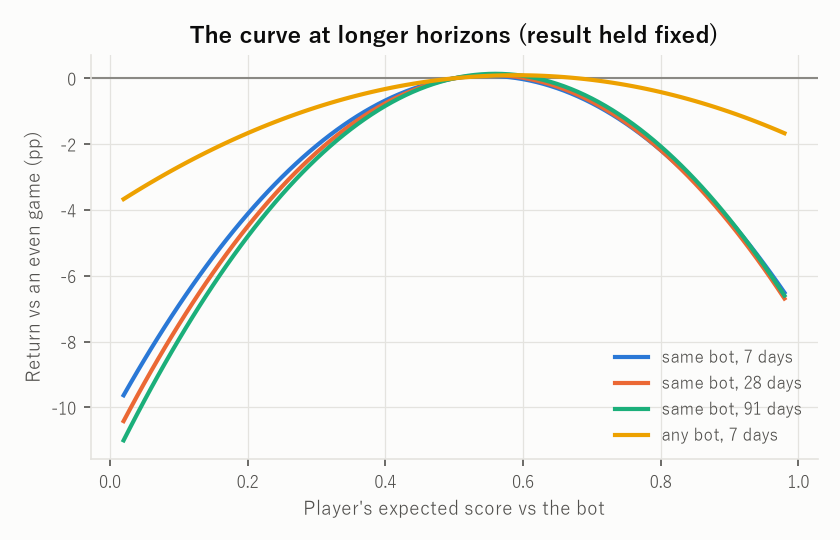

In [15]:
# figure: the curves implied by the within-player horizon models, relative to es = 0.5
grid = np.linspace(0.02, 0.98, 97)
fig, (ax,) = new_figure(1, width=5.6, height=3.6)
ax.axhline(0, color=NEUTRAL, linewidth=1)
shown = [("same bot", 7, SERIES[0]), ("same bot", 28, SERIES[1]), ("same bot", 91, SERIES[2]),
         ("any bot", 7, SERIES[3])]
for target, days, color in shown:
    row = next(
        r for r in horizons if (r["target"], r["days"], r["within"]) == (target, days, "player")
    )
    change = row["es"] * grid + row["es2"] * grid**2 - (row["es"] * 0.5 + row["es2"] * 0.25)
    ax.plot(grid, 100 * change, color=color, label=f"{target}, {days} days")
ax.set_xlabel("Player's expected score vs the bot")
ax.set_ylabel("Return vs an even game (pp)")
ax.set_title("The curve at longer horizons (result held fixed)")
ax.legend()
display(Image(filename=save_figure(fig, FIGURE_DIR / "d1_horizons.png")))

### 2.4 逆U字の検定：2直線の検定

9本のモデルのそれぞれで、曲線が山の形かどうかを判定する（Q2a〜Q2e）。この段階の逆U字の判定は、この検定だけで行う。

#### なぜ必要か

- es² の項 $c$ が負であることが示すのは、曲線が上に凸であることだけである。頂点 $-b / (2c)$ がデータの範囲の外にあれば、範囲の中の曲線は上がるだけか、下がるだけである（Lind & Mehlum, 2010；Haans et al., 2016）。
- さらに、真の曲線が上がってから平らになるだけのときにも、2次式による検定は偽の頂点を示しうる（Simonsohn, 2018）。
- そこで、2次式を使わずに山の両側を別々の直線で表す、2直線の検定（Simonsohn, 2018）で逆U字を判定する。

#### 手順

Simonsohn（2018）の公開コード（twolines.R, v0.52）の手順に従う。

1. **向きを決める。** es と es² の2次式を当てはめ、es の最小値での傾きが正なら逆U字の向き（山）、そうでなければU字の向き（谷）として、以下を進める。
2. **一般化加法モデルを当てはめる。** es の3次回帰スプライン（基底の数10、節点は es の異なる値に等間隔に置く）と、2次式以外の統制変数を入れた一般化加法モデルを `fit_fe_gam()` で当てはめる（Wood, 2017）。滑らかさは一般化交差検証（GCV）で選ぶ。
3. **平らな上部を決める。** es の10〜90パーセンタイルの範囲のセッションについて、モデルの予測値 $\hat y$ とその標準誤差 $\mathrm{se}$ を求める。山の向きなら、$\hat y + \mathrm{se}$ がその範囲での $\hat y$ の最大値を超えるセッションの es を「平らな上部」$x_\mathrm{flat}$ とする（`flat_top()`）。
4. **最初の区切り。** 区切り $x_c$ を $x_\mathrm{flat}$ の中央値に置き、2本の直線を当てはめる（下の5）。
5. **2本の直線。** 主なモデルの $b\,\mathrm{es} + c\,\mathrm{es}^2$ を、次の3項に置き換えて `fit_fe_lpm()` で推定する（`split_at()`、`two_slopes()`）。
   - `es_low` = $\mathrm{es} - x_c$（区切りより難しい側。それ以外は0）：難しい側の傾き $b_1$
   - `es_high` = $\mathrm{es} - x_c$（区切りより易しい側。それ以外は0）：易しい側の傾き $b_2$
   - `high`：易しい側なら1。区切りでの段差を許す。
   - 区切りちょうどの es は、$b_1$ を推定する回帰では難しい側に、$b_2$ を推定する回帰では易しい側に入れる。原法と同じく、1本の直線につき1回、計2回当てはめる。
6. **区切りを動かす（Robin Hood 法）。** 4で得た2本の傾きの $|z_1|$、$|z_2|$ から、区切りを $x_\mathrm{flat}$ の $|z_2| / (|z_1| + |z_2|)$ 分位点に移し、もう一度2本の直線を当てはめる（`robin_hood()`）。弱い（|z| が小さい）直線により多くのデータを与えるためである。報告するのはこの2回目の推定である。
7. **判定。** $b_1$ と $b_2$ の符号が逆で、どちらも両側 p < 0.05 なら、U字または逆U字と判定する。

#### 原法との違い

- **プレイヤーの固定効果。** 原法は固定効果を想定しない。ここでは、主なモデルと同じく、一般化加法モデルにも2本の直線にもプレイヤー（ペア内のモデルでは組）の固定効果を入れる。
  - `fit_fe_gam()` は、スプラインの基底とほかのすべての列から各プレイヤーの平均を引き、罰則付き最小二乗法を当てはめる。罰則のない固定効果を取り除いても、残りの推定値は変わらない（Frisch–Waugh–Lovell の定理；Wooldridge, 2010）。
  - GCV の有効自由度には、固定効果の数を足す。
  - 予測値は、統制変数を平均に置いたときの値から定数を除いたもの（スプラインの部分）である。予測値の差は定数によらないが、標準誤差もスプラインの部分だけのものなので、原法の標準誤差（定数の不確かさを含む）とは少し異なる。
- **2本の直線の標準誤差。** 原法は HC3 を使う。ここでは、同じプレイヤーのセッションが独立でないので、ほかのモデルと同じくプレイヤー単位のクラスター頑健標準誤差を使う（Cameron & Miller, 2015）。

#### 設定

- 2.3の9本のモデル（対局の結果を入れる）すべてに適用する。
- 7日の同じボットへの再訪・プレイヤー内のモデルでは、対局の結果を入れない場合も推定する（Q2c で、入れる場合と比べるため）。
- ペア内のモデルでは、一般化加法モデルにも2本の直線にも、プレイヤーの代わりにプレイヤーとボットの組の固定効果を入れる。標準誤差はどのモデルでもプレイヤー単位でクラスター化する。

#### 表の読み方

- `target`、`days`、`within`：2.3の表と同じモデルの区別。`with_result`：対局の結果を入れたか。
- `shape`：手順1の向き（`inverted U` なら山）。
- `gam_edf`：一般化加法モデルのスプラインの有効自由度。
- `flat_low`〜`flat_high`：平らな上部の es の範囲。区切りを決めるための手順の一部で、標本が大きいほど狭くなるので、頂上の幅を表すものではない。`breakpoint_first`、`breakpoint`：最初の区切りと、Robin Hood 法で動かした区切り。
- `slope_hard`、`slope_easy`：$b_1$ と $b_2$（es が1増えたときの再訪の変化。0.1増えたときは、その10分の1）。それぞれの95%区間と p 値。`slope_hard_z`、`slope_easy_z` は z 統計量（傾き ÷ 標準誤差。標準誤差は95%区間の幅から求める）。
- `u_shape`：手順7の判定。

#### 確認すべき点

すべての行で、`shape` が `inverted U` で、`u_shape` が true であること。

定義の後の検査では、人工データを使って次を確かめる。

- 節点が mgcv の置き方と同じになり、罰則行列が直線を罰しないこと。
- 一般化加法モデルが、プレイヤーごとの水準の違いがあっても、人工の山の形を復元すること。
- 平らな上部、2本の直線の変数、Robin Hood 法の区切りが、既知の答えを返すこと。
- 人工の折れ線のデータから、2本の傾きが復元されること。

In [16]:
GAM_BASIS = 10  # basis size of the cubic regression spline, as in twolines.R (k = 10)
GAM_LOG_LAMBDAS = np.linspace(-20.0, 20.0, 81)  # smoothing parameters searched (log, rescaled)
MIDDLE = (0.1, 0.9)  # quantiles of es between which the flat top is sought


def place_knots(x: np.ndarray, n_knots: int) -> np.ndarray:
    """Knots of mgcv's cubic regression spline: spread evenly through the unique values."""
    unique = np.unique(x)
    delta = (unique.size - 1) / (n_knots - 1)
    steps = delta * np.arange(1, n_knots - 1)
    lower = np.floor(steps).astype(int)
    frac = steps - lower
    inner = unique[lower] * (1 - frac) + unique[np.minimum(lower + 1, unique.size - 1)] * frac
    return np.concatenate([[unique[0]], inner, [unique[-1]]])


def cr_basis(x: np.ndarray, knots: np.ndarray) -> np.ndarray:
    """Cubic regression spline basis; its coefficients are the curve's values at the knots."""
    return np.asarray(patsy.dmatrix(
        "cr(x, knots=inner, lower_bound=low, upper_bound=high) - 1",
        {"x": x, "inner": knots[1:-1], "low": knots[0], "high": knots[-1]},
    ))


def cr_penalty(knots: np.ndarray) -> np.ndarray:
    """Integrated squared second derivative of the spline, as a matrix in its coefficients."""
    h = np.diff(knots)
    k = knots.size
    d = np.zeros((k - 2, k))
    b = np.zeros((k - 2, k - 2))
    for i in range(k - 2):
        d[i, i], d[i, i + 1], d[i, i + 2] = 1 / h[i], -1 / h[i] - 1 / h[i + 1], 1 / h[i + 1]
        b[i, i] = (h[i] + h[i + 1]) / 3
        if i < k - 3:
            b[i, i + 1] = b[i + 1, i] = h[i + 1] / 6
    return d.T @ np.linalg.solve(b, d)


@dataclass(frozen=True)
class SmoothFit:
    """A fitted smooth of one variable: its basis, coefficients and their covariance."""

    knots: np.ndarray
    constraint: np.ndarray  # maps the centred coefficients to the knot values
    coef: np.ndarray
    cov: np.ndarray  # Bayesian covariance of coef, as mgcv's Vp
    edf: float

    def predict(self, x: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """The smooth and its standard error at x."""
        basis = cr_basis(x, self.knots) @ self.constraint
        se = np.sqrt(np.einsum("ij,jk,ik->i", basis, self.cov, basis))
        return basis @ self.coef, se


def demean(values: np.ndarray, keys: np.ndarray) -> np.ndarray:
    """Subtracts each group's mean from every column."""
    return values - pd.DataFrame(values).groupby(keys).transform("mean").to_numpy()


def fit_fe_gam(
    df: pd.DataFrame, formula: str, smooth: str, fe: str, knots: np.ndarray | None = None
) -> SmoothFit:
    """Gaussian GAM: a spline in `smooth`, the linear terms of `formula`, fixed effects for `fe`.

    The smoothing parameter minimises GCV (Wood, 2017). Knots are placed as mgcv does unless given.
    """
    data = df.dropna(subset=[fe, smooth])
    y, x = patsy.dmatrices(formula, data, return_type="dataframe")
    x = x.drop(columns=[c for c in x.columns if c == "Intercept"])
    used = data.loc[x.index, fe]
    informative = (used.groupby(used).transform("size") > 1).to_numpy()
    y, x = y[informative], x[informative]
    keys = data.loc[x.index, fe].to_numpy()
    s = data.loc[x.index, smooth].to_numpy(dtype=float)
    knots = place_knots(s, GAM_BASIS) if knots is None else knots
    basis = cr_basis(s, knots)
    # sum-to-zero constraint, as mgcv: drop the direction of the basis column sums
    q, _ = np.linalg.qr(basis.sum(axis=0)[:, None], mode="complete")
    constraint = q[:, 1:]
    linear = demean(x.to_numpy(dtype=float), keys)
    linear = linear[:, np.abs(linear).sum(axis=0) > 1e-12]
    z = np.hstack([linear, demean(basis @ constraint, keys)])
    y_dm = demean(y.to_numpy(dtype=float), keys)[:, 0]
    m, r, yy = z.T @ z, z.T @ y_dm, float(y_dm @ y_dm)
    n_lin = linear.shape[1]
    penalty = np.zeros_like(m)
    penalty[n_lin:, n_lin:] = constraint.T @ cr_penalty(knots) @ constraint
    scale = np.linalg.norm(m[n_lin:, n_lin:]) / np.linalg.norm(penalty)
    n, n_groups = y_dm.size, np.unique(keys).size

    def fit(log_lambda: float) -> tuple[float, np.ndarray, np.ndarray, float, float]:
        a = m + scale * math.exp(log_lambda) * penalty
        beta = np.linalg.solve(a, r)
        rss = yy - 2 * beta @ r + beta @ m @ beta
        edf_terms = np.diag(np.linalg.solve(a, m))
        dof = n - n_groups - edf_terms.sum()
        return n * rss / dof**2, beta, a, rss / dof, float(edf_terms[n_lin:].sum())

    best = min(GAM_LOG_LAMBDAS, key=lambda v: fit(v)[0])
    step = GAM_LOG_LAMBDAS[1] - GAM_LOG_LAMBDAS[0]
    refined = optimize.minimize_scalar(
        lambda v: fit(v)[0], bounds=(best - step, best + step), method="bounded"
    )
    _, beta, a, sigma2, edf = fit(float(refined.x))
    cov = sigma2 * np.linalg.inv(a)
    return SmoothFit(knots, constraint, beta[n_lin:], cov[n_lin:, n_lin:], edf)


def flat_top(x: np.ndarray, fit: np.ndarray, se: np.ndarray, *, inverted: bool) -> np.ndarray:
    """The x values whose fit is within 1 SE of the most extreme fit (twolines.R)."""
    if inverted:
        return x[fit + se > fit.max()]
    return x[fit - se < fit.min()]


def split_at(frame: pd.DataFrame, breakpoint: float, *, break_low: bool) -> pd.DataFrame:
    """Adds the two-lines terms; the breakpoint itself joins the low side if break_low."""
    low = frame["es"] <= breakpoint if break_low else frame["es"] < breakpoint
    gap = frame["es"] - breakpoint
    return frame.assign(
        es_low=np.where(low, gap, 0.0), es_high=np.where(low, 0.0, gap), high=(~low).astype(int)
    )


def two_slopes(
    frame: pd.DataFrame, breakpoint: float, formula: str, within: str
) -> dict[str, dict[str, float]]:
    """The slope below and above the breakpoint, each from its own fit (twolines.R)."""
    slopes = {}
    for side, term, break_low in (("hard", "es_low", True), ("easy", "es_high", False)):
        data = split_at(frame, breakpoint, break_low=break_low)
        model = fit_fe_lpm(data, formula, within, "player", f"two lines, {side} side")
        slopes[side] = {**model.term(term), "n_obs": model.n_obs}
    return slopes


def robin_hood(flat_es: np.ndarray, z_hard: float, z_easy: float) -> float:
    """Moves the breakpoint so that the weaker line gets more data (Simonsohn, 2018)."""
    return float(np.quantile(flat_es, abs(z_easy) / (abs(z_hard) + abs(z_easy))))


def z_value(slope: dict[str, float]) -> float:
    """The z statistic of a slope."""
    return slope["estimate"] / slope["std_err"]


def two_lines_specs() -> list[dict[str, Any]]:
    """The nine horizon models (result held fixed), and the 7-day same-bot one without it."""
    base = {
        "target": "same bot", "days": 7, "within": "player", "outcome": "return_7d",
        "flag": "session_last", "with_result": False,
    }
    specs = [base]
    for days in RETURN_WINDOWS_D:
        for outcome, flag, target in return_targets(days):
            for within in comparisons(target):
                specs.append({
                    "target": target, "days": days, "within": within, "outcome": outcome,
                    "flag": flag, "with_result": True,
                })
    return specs


def two_lines(
    panel: pl.DataFrame, *, outcome: str, flag: str, within: str, with_result: bool
) -> dict[str, Any]:
    """Two-lines test (Simonsohn, 2018) of a return model in es, within player or pair."""
    data = panel.filter(pl.col(flag) & pl.col(outcome).is_not_null())
    frame = to_model_frame(data, [outcome, *FRAME_COLUMNS])
    rest = f"{OUTCOME_TERM + ' + ' if with_result else ''}n_plies_100 + {CONTROLS} + C(month)"
    es = frame["es"].dropna().to_numpy()
    # 1. direction: the quadratic's slope at the lowest es
    quadratic = fit_fe_lpm(frame, f"{outcome} ~ {ES} + {ES2} + {rest}", within, "player", "q")
    inverted = quadratic.term(ES)["estimate"] + 2 * quadratic.term(ES2)["estimate"] * es.min() > 0
    # 2-3. flat top of the GAM within the middle 80% of es
    smooth = fit_fe_gam(frame, f"{outcome} ~ {rest}", "es", within)
    low, high = np.quantile(es, MIDDLE)
    middle = es[(es > low) & (es < high)]
    values, index = np.unique(middle, return_inverse=True)
    fit, se = smooth.predict(values)
    flat = flat_top(middle, fit[index], se[index], inverted=inverted)
    # 4-6. lines at the median of the flat top, then at the Robin Hood breakpoint
    first_break = float(np.median(flat))
    lines = f"{outcome} ~ es_low + es_high + high + {rest}"
    first = two_slopes(frame, first_break, lines, within)
    breakpoint = robin_hood(flat, z_value(first["hard"]), z_value(first["easy"]))
    hard, easy = two_slopes(frame, breakpoint, lines, within).values()
    return {
        "n_obs": hard["n_obs"],
        "shape": "inverted U" if inverted else "U", "gam_edf": smooth.edf,
        "flat_low": float(flat.min()), "flat_high": float(flat.max()),
        "breakpoint_first": first_break, "breakpoint": breakpoint,
        "slope_hard": hard["estimate"], "slope_hard_ci_low": hard["ci_low"],
        "slope_hard_ci_high": hard["ci_high"], "slope_hard_p": hard["p_value"],
        "slope_easy": easy["estimate"], "slope_easy_ci_low": easy["ci_low"],
        "slope_easy_ci_high": easy["ci_high"], "slope_easy_p": easy["p_value"],
        "u_shape": bool(
            hard["estimate"] * easy["estimate"] < 0
            and hard["p_value"] < ALPHA and easy["p_value"] < ALPHA
        ),
    }


# check 1: knots as mgcv places them, and a penalty that leaves straight lines alone
knots = place_knots(np.arange(11.0), 5)
assert np.allclose(knots, [0.0, 2.5, 5.0, 7.5, 10.0])
uneven = np.array([0.0, 0.1, 0.35, 0.5, 0.8, 1.0])
assert np.allclose(cr_penalty(uneven) @ uneven, 0.0) and np.allclose(cr_penalty(uneven).sum(1), 0)

# check 2: a made-up hill (top at 0.5) is recovered despite player levels and a covariate
rng = np.random.default_rng(2)
hill_player = np.repeat(np.arange(400), 25)
hill_es = rng.uniform(size=hill_player.size)
hill_z = rng.normal(size=hill_player.size)
hill = pd.DataFrame({
    "y": -((hill_es - 0.5) ** 2) + 0.2 * hill_z + rng.normal(size=400)[hill_player]
    + rng.normal(scale=0.05, size=hill_player.size),
    "es": hill_es, "z": hill_z, "player": hill_player,
})
hill_fit = fit_fe_gam(hill, "y ~ z", "es", "player")
grid_es = np.linspace(0.05, 0.95, 91)
grid_fit, _ = hill_fit.predict(grid_es)
assert abs(grid_es[np.argmax(grid_fit)] - 0.5) < 0.05
truth = -((grid_es - 0.5) ** 2)
assert np.allclose(grid_fit - grid_fit.mean(), truth - truth.mean(), atol=0.01)

# check 3: the flat top, the two-lines terms, and the Robin Hood breakpoint
assert flat_top(np.array([0.1, 0.2, 0.3]), np.array([0.0, 1.0, 0.9]), np.array([0.15] * 3),
                inverted=True).tolist() == [0.2, 0.3]
split = split_at(pd.DataFrame({"es": [0.2, 0.5, 0.8]}), 0.5, break_low=True)
assert np.allclose(split["es_low"], [-0.3, 0.0, 0.0]) and split["high"].tolist() == [0, 0, 1]
split = split_at(pd.DataFrame({"es": [0.2, 0.5, 0.8]}), 0.5, break_low=False)
assert np.allclose(split["es_high"], [0.0, 0.0, 0.3]) and split["high"].tolist() == [0, 1, 1]
assert math.isclose(robin_hood(np.linspace(0, 1, 101), 3.0, -1.0), 0.25)

# check 4: a made-up kinked curve (rising 0.3, falling 0.1, kink at 0.5) is recovered
kink_player = np.repeat(np.arange(300), 30)
kink_es = rng.uniform(size=kink_player.size)
kink_y = np.where(kink_es < 0.5, 0.3 * (kink_es - 0.5), -0.1 * (kink_es - 0.5))
kinked = split_at(pd.DataFrame({
    "y": kink_y + rng.normal(scale=0.05, size=kink_es.size), "es": kink_es, "player": kink_player,
}), 0.5, break_low=True)
fit = fit_fe_lpm(kinked, "y ~ es_low + es_high + high", "player", "player", "kinked")
assert abs(fit.term("es_low")["estimate"] - 0.3) < 0.02
assert abs(fit.term("es_high")["estimate"] + 0.1) < 0.02
print("checks passed")

checks passed


In [17]:
def find_spec(target: str, days: int, within: str, *, with_result: bool) -> dict[str, Any]:
    """The model of two_lines_specs() with these labels."""
    wanted = (target, days, within, with_result)
    return next(
        s for s in two_lines_specs()
        if (s["target"], s["days"], s["within"], s["with_result"]) == wanted
    )


MAIN_SPEC = find_spec("same bot", 7, "player", with_result=True)  # the main model of 2.2
FREE_SPEC = find_spec("same bot", 7, "player", with_result=False)  # the same, result free
SPEC_LABELS = ("target", "days", "within", "with_result")


def spec_key(spec: dict[str, Any]) -> str:
    """Short name of a model, used in the names of saved fits."""
    result = "result" if spec["with_result"] else "no_result"
    return f"{spec['target'].replace(' ', '_')}_{spec['days']}d_{spec['within']}_{result}"


def spec_label(spec: dict[str, Any]) -> str:
    """Readable name of a model."""
    result = "result held fixed" if spec["with_result"] else "result free"
    return f"{spec['target']}, {spec['days']} d, within {spec['within']}, {result}"


def spec_columns(spec: dict[str, Any]) -> dict[str, Any]:
    """The labels of a model, as columns of a table row."""
    return {key: spec[key] for key in SPEC_LABELS}


def control_terms(spec: dict[str, Any]) -> str:
    """The model's right-hand side without the curve terms."""
    result = f"{OUTCOME_TERM} + " if spec["with_result"] else ""
    return f"{result}n_plies_100 + {CONTROLS} + C(month)"

In [18]:
shape_tests = [
    {
        **spec_columns(spec),
        **cached(f"panel_two_lines_{spec_key(spec)}", lambda spec=spec: two_lines(
            panel_games(), outcome=spec["outcome"], flag=spec["flag"], within=spec["within"],
            with_result=spec["with_result"],
        )),
    }
    for spec in two_lines_specs()
]
# z of each slope, from its 95% interval (estimate +- Z95 * se)
for row in shape_tests:
    for side in ("hard", "easy"):
        se = (row[f"slope_{side}_ci_high"] - row[f"slope_{side}_ci_low"]) / (2 * Z95)
        row[f"slope_{side}_z"] = row[f"slope_{side}"] / se
pl.DataFrame(shape_tests)

target,days,within,with_result,n_obs,shape,gam_edf,flat_low,flat_high,breakpoint_first,…,slope_hard_ci_low,slope_hard_ci_high,slope_hard_p,slope_easy,slope_easy_ci_low,slope_easy_ci_high,slope_easy_p,u_shape,slope_hard_z,slope_easy_z
str,i64,str,bool,i64,str,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,bool,f64,f64
"""same bot""",7,"""player""",false,1031565,"""inverted U""",8.930452,0.449801,0.547349,0.497122,…,0.218089,0.256823,1.3193e-127,-0.062148,-0.08214,-0.042156,1.1098e-9,true,24.030994,-6.092762
"""same bot""",7,"""pair""",true,909970,"""inverted U""",7.740781,0.429947,0.525881,0.47699,…,0.119324,0.170151,6.2197e-29,-0.110395,-0.137373,-0.083417,1.0557e-15,true,11.162529,-8.020203
"""same bot""",7,"""player""",true,1031565,"""inverted U""",8.92698,0.428537,0.521573,0.474119,…,0.217174,0.257219,2.9374e-119,-0.074851,-0.09421,-0.055492,3.5059e-14,true,23.21885,-7.578124
"""any bot""",7,"""player""",true,888077,"""inverted U""",4.207731,0.456934,0.586895,0.5187,…,0.071781,0.097068,3.8916e-39,-0.021844,-0.036137,-0.007551,0.002741,true,13.087307,-2.99533
"""same bot""",28,"""pair""",true,887900,"""inverted U""",8.86642,0.437015,0.533051,0.484175,…,0.119191,0.164248,6.2771e-35,-0.082186,-0.105144,-0.059227,2.2806e-12,true,12.329582,-7.016152
"""same bot""",28,"""player""",true,1006355,"""inverted U""",8.966429,0.427128,0.52301,0.474119,…,0.239011,0.277371,2.0883e-153,-0.066389,-0.083334,-0.049445,1.5996e-14,true,26.384055,-7.679303
"""any bot""",28,"""player""",true,867170,"""inverted U""",4.826423,0.446953,0.571463,0.507195,…,0.072935,0.096084,1.8893e-46,-0.014088,-0.025006,-0.003169,0.011444,true,14.310213,-2.528854
"""same bot""",91,"""pair""",true,821732,"""inverted U""",8.949011,0.456934,0.557312,0.505756,…,0.109841,0.15121,3.8856e-35,-0.078132,-0.101369,-0.054894,4.3970e-11,true,12.368172,-6.590042
"""same bot""",91,"""player""",true,930176,"""inverted U""",8.982539,0.432771,0.535916,0.484175,…,0.24709,0.286835,8.8036e-153,-0.057074,-0.073409,-0.040739,7.4848e-12,true,26.329544,-6.848078


#### 図1のコード

図1は、モデルを使わない生の値と、2直線の検定の曲線を並べる。

- `session_ends()`：7日再訪が判明している各セッションの最後の対局を残す。
- `binned_return()`：幅0.05の期待スコアのビンごとに、セッション数と7日以内の再訪数を数える。続くセルは、49か月それぞれでこの数を集める（または保存済みの結果を読み込む）。
- `wilson_interval()`：割合の Wilson の95%区間（Wilson, 1927）。
- `two_lines_curve()`：2直線の検定の手順2の一般化加法モデルを当て直し、es の格子の上での曲線とその標準誤差を返す。図に描くためだけのもので、判定には使わない。当て直した曲線の有効自由度が、上の表の `gam_edf` と一致することを確かめる（`assert`）。

In [19]:
BIN_WIDTH = 0.05


def session_ends(games: pl.DataFrame) -> pl.DataFrame:
    """Last games of sessions whose 7-day return is known."""
    return games.filter(pl.col("session_last") & pl.col("return_7d").is_not_null())


def binned_return(sessions: pl.DataFrame) -> pl.DataFrame:
    """Sessions (n) and 7-day returns (k) per expected-score bin, labelled by its middle."""
    n_bins = round(1 / BIN_WIDTH)
    middle = (pl.col("es") / BIN_WIDTH).floor().clip(0, n_bins - 1) * BIN_WIDTH + BIN_WIDTH / 2
    return (
        sessions.with_columns(middle.alias("es_mid"))
        .group_by("es_mid")
        .agg(pl.len().alias("n"), pl.col("return_7d").cast(pl.Float64).sum().alias("k"))
        .sort("es_mid")
    )


made_up = pl.DataFrame({
    "session_last": [True, True, False, True], "return_7d": [True, False, True, None],
    "es": [0.51, 0.53, 0.1, 0.9],
})
assert session_ends(made_up).height == 2
assert binned_return(session_ends(made_up)).to_dicts() == [{"es_mid": 0.525, "n": 2, "k": 1.0}]
print("checks passed")

checks passed


In [20]:
def binned_month(month: str) -> list[dict[str, Any]]:
    """The binned session and return counts of one month."""
    return binned_return(session_ends(load_month(month, bots))).to_dicts()


binned_months = {m: cached(f"binned_{m}", lambda m=m: binned_month(m)) for m in STUDY_MONTHS}

In [21]:
def wilson_interval(successes: float, n: float) -> tuple[float, float]:
    """95% Wilson score interval of a proportion."""
    p = successes / n
    denom = 1 + Z95**2 / n
    centre = (p + Z95**2 / (2 * n)) / denom
    half = Z95 * math.sqrt(p * (1 - p) / n + Z95**2 / (4 * n * n)) / denom
    return centre - half, centre + half


CURVE_POINTS = 99  # grid points of a drawn smooth


def two_lines_curve(panel: pl.DataFrame, spec: dict[str, Any]) -> dict[str, Any]:
    """The GAM of a two-lines test (its step 2) on a grid of es, for drawing only."""
    data = panel.filter(pl.col(spec["flag"]) & pl.col(spec["outcome"]).is_not_null())
    frame = to_model_frame(data, [spec["outcome"], *FRAME_COLUMNS])
    formula = f"{spec['outcome']} ~ {control_terms(spec)}"
    smooth = fit_fe_gam(frame, formula, "es", spec["within"])
    grid = np.linspace(smooth.knots[0], smooth.knots[-1], CURVE_POINTS)
    fit, se = smooth.predict(grid)
    return {"edf": smooth.edf, "es": grid.tolist(), "fit": fit.tolist(), "se": se.tolist()}


# check: Wilson's interval holds the proportion and narrows with n
low, high = wilson_interval(30, 100)
wide_low, wide_high = wilson_interval(300, 1000)
assert low < 0.3 < high and wide_high - wide_low < high - low
print("checks passed")

checks passed


In [22]:
def two_lines_row(spec: dict[str, Any]) -> dict[str, Any]:
    """The row of shape_tests for a model."""
    return next(r for r in shape_tests if all(r[k] == spec[k] for k in SPEC_LABELS))


curves = {
    spec_key(spec): cached(
        f"panel_two_lines_curve_{spec_key(spec)}",
        lambda spec=spec: two_lines_curve(panel_games(), spec),
    )
    for spec in (FREE_SPEC, MAIN_SPEC)
}
# the redrawn smooth is the one the test used
for spec in (FREE_SPEC, MAIN_SPEC):
    assert math.isclose(curves[spec_key(spec)]["edf"], two_lines_row(spec)["gam_edf"], rel_tol=1e-6)

#### 図の読み方

図「再訪の曲線」：

- 左：モデルを使わない生の値。49か月分の月ごとの表を合算し、期待スコアごとに、7日以内の再訪があったセッションの割合を Wilson の95%区間とともに示す。セッションが100未満のビンは省く。プレイヤーの間の違い（例えば、とても難しい相手やとても易しい相手と指す人は、もともと戻りにくい）を含むので、下がり方の大きさは、同じプレイヤーの中で比べた値（段階3の Binscatter）よりずっと大きい。
- 中・右：2直線の検定（7日・同じボット・プレイヤー内、4年分のパネル。中は結果を統制しない、右は統制する）。
  - 青い線と帯：一般化加法モデルの es の曲線（スプラインの部分で、データの上の平均が0になるよう中心化したもの）と、その95%区間。
  - 灰色の帯：平らな上部。点線：区切り。
  - 破線の2本：難しい側と易しい側の直線。凡例に、es が0.1増えたときの再訪の変化（ポイント）と p 値を示す。直線の高さはプレイヤーの固定効果に吸収されて推定されないので、区切りでの曲線の値を通るように描いた。推定値なのは傾きだけである。

#### 出力の読み方

- 10本すべてで `shape` が `inverted U`、`u_shape` が true である。区切りはどれも es 0.45〜0.49 にある。
- 図の2本の直線は、難しい側で上がり（傾きが正）、易しい側で下がる（傾きが負）。どちらも有意なので、山の形（逆U字）と判定される。

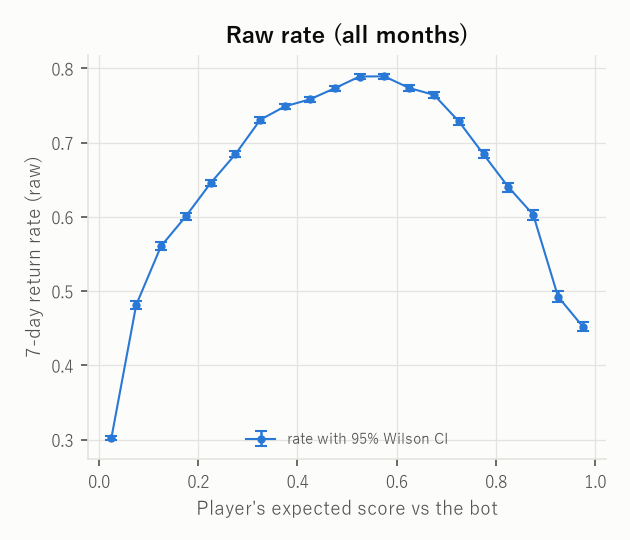

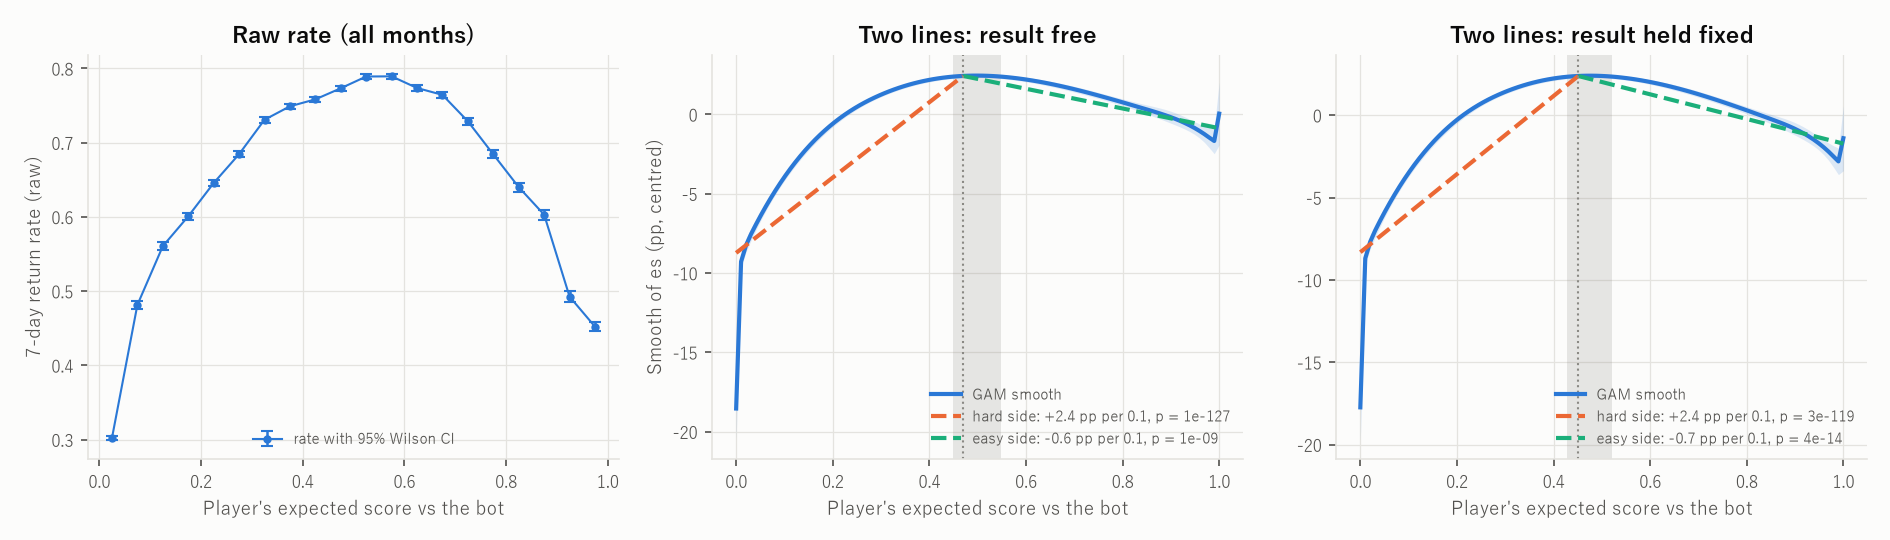

In [23]:
# figure 1: the raw rate over all monthly tables, and the two-lines test
binned = (
    pl.DataFrame([row for rows in binned_months.values() for row in rows])
    .group_by("es_mid")
    .agg(pl.col("n").sum(), pl.col("k").sum())
    .sort("es_mid")
    .with_columns((pl.col("k") / pl.col("n")).alias("rate"))
)
shown_bins = binned.filter(pl.col("n") >= 100)
bounds = [wilson_interval(k, n) for k, n in zip(shown_bins["k"], shown_bins["n"], strict=True)]
raw_rate = shown_bins["rate"].to_numpy()
raw_low, raw_high = (np.array(side) for side in zip(*bounds, strict=True))


def draw_raw_rate(ax: Axes) -> None:
    """Draws the raw 7-day return rate per es bin with its Wilson intervals on ax."""
    # error bars with caps, since a shaded band of at most 1.5 points hides under the markers
    ax.errorbar(
        shown_bins["es_mid"].to_numpy(), raw_rate, yerr=[raw_rate - raw_low, raw_high - raw_rate],
        color=SERIES[0], marker="o", markersize=3, linewidth=1, elinewidth=1.2, capsize=3,
        label="rate with 95% Wilson CI",
    )
    ax.set_xlabel("Player's expected score vs the bot")
    ax.set_ylabel("7-day return rate (raw)")
    ax.set_title("Raw rate (all months)")
    ax.legend(fontsize=7, loc="lower center")


# the raw rate alone, for the paper's figure 1
raw_fig, (raw_ax,) = new_figure(1, width=4.2, height=3.6)
draw_raw_rate(raw_ax)
display(Image(filename=save_figure(raw_fig, FIGURE_DIR / "d1_return_raw.png")))

fig, (ax_raw, ax_free, ax_main) = new_figure(3, width=4.2, height=3.6)
draw_raw_rate(ax_raw)
for ax, spec in zip((ax_free, ax_main), (FREE_SPEC, MAIN_SPEC), strict=True):
    curve, test = curves[spec_key(spec)], two_lines_row(spec)
    es_grid, smooth, smooth_se = (np.array(curve[key]) for key in ("es", "fit", "se"))
    ax.axvspan(test["flat_low"], test["flat_high"], color=NEUTRAL, alpha=0.2, lw=0)
    ax.fill_between(
        es_grid, 100 * (smooth - Z95 * smooth_se), 100 * (smooth + Z95 * smooth_se),
        color=SERIES[0], alpha=0.15, lw=0,
    )
    ax.plot(es_grid, 100 * smooth, color=SERIES[0], label="GAM smooth")
    breakpoint = test["breakpoint"]
    at_break = float(np.interp(breakpoint, es_grid, smooth))
    sides = (
        ("hard", es_grid[0], breakpoint, SERIES[1]), ("easy", breakpoint, es_grid[-1], SERIES[2])
    )
    for side, left, right, color in sides:
        slope, p_value = test[f"slope_{side}"], test[f"slope_{side}_p"]
        xs = np.array([left, right])
        ax.plot(
            xs, 100 * (at_break + slope * (xs - breakpoint)), color=color, linestyle="--",
            label=f"{side} side: {10 * slope:+.1f} pp per 0.1, p = {p_value:.1g}",
        )
    ax.axvline(breakpoint, color=NEUTRAL, linestyle=":", linewidth=1)
    ax.set_xlabel("Player's expected score vs the bot")
    ax.set_title("Two lines: " + spec_label(spec).split(", ", 3)[-1])
    ax.legend(fontsize=7)
ax_free.set_ylabel("Smooth of es (pp, centred)")
display(Image(filename=save_figure(fig, FIGURE_DIR / "d1_return_curve.png")))

## 3. 左右差：互角から同じだけ離れたときの違い

### 問いと進め方

段階2で、再訪が期待スコアについて逆U字になることを確かめた。この段階では、互角から同じだけ離れたとき、難しい側と易しい側のどちらで再訪が大きく下がるかを調べる。2次式は頂点の左右で同じ形を仮定するので、左右の違いは測れない。そこで、形を仮定しない Binscatter を使う。使うのは段階2のモデルだけで、新しい標本、新しい結果の変数、プレイヤーのグループどうしの比較は加えない。

問いは次の1つである。

- Q3b：互角から同じだけ離れたとき、難しい側と易しい側のどちらで再訪が大きく下がるか（非対称性）。

次の順に答える。

- 3.1：Binscatter を定め、主なモデル（結果を統制する場合としない場合）に当てはめて、両端の低下を見る。続けて、2.3の9本のモデルと結果を統制しない7日のモデルの計10本に広げ、ビンどうしの共分散を保存する（Q3b の土台）。
- 3.2：鏡像差の検定で、互角から同じだけ離れた難しい側と易しい側を比べる（Q3b）。

この段階の向きの約束：es では小さい側（左）が難しい側である。

### 3.1 Binscatter

互角の対局の後と比べて、難しい側と易しい側で再訪がどれだけ下がるかを、2次式を仮定せずに見る。

- **Binscatter**：$b\,\mathrm{es} + c\,\mathrm{es}^2$ の代わりに、es を21のビン（区切り）に分け、ビンごとのダミーを入れたモデルである。名称は Cattaneo et al. (2024) に従う。
  - ビンは0, 0.05, …, 1を中央とする幅0.05の区切りで、境目は0.025, 0.075, …, 0.975である（各ビンは左端を含み右端を含まない）。es は0〜1に収まるので、両端のビン（0〜0.025と0.975〜1）だけは幅が半分になる。
  - 基準は互角（es = 0.5）を中央に持つ0.475〜0.525のビンで、各ビンの係数は「基準ビンと比べて、再訪が何ポイント違うか」を表す。0.5を中央に置くことで、ビンは基準を挟んで左右対称に並ぶ。
  - このモデルの曲線は、ビンの中では一定で、ビンの境目で跳ぶ**階段関数**である（James et al., 2021, 7章）。2次式のような形を仮定しない代わりに、ビンの中での変化は表せない。
  - 図では、ビンごとの推定値を点で示し、点を線で結ぶ。この線は見やすくするためだけのもので、ビンの間の値を推定したものではない。
  - 統制変数は、プレイヤーの固定効果も含めて、ビンのダミーと同じ最小二乗法で一緒に推定する。Cattaneo et al. (2024) は、この推定を共変量で調整した Binscatter と呼ぶ。統制変数を先に取り除いてから再訪をビンごとに平均する方法では、曲線の形を誤りうる（Cattaneo et al., 2024）。
  - ビンの幅0.05は、データを見ずに決めた。Cattaneo et al. (2024) によれば、実務ではビンの数をデータと無関係に10か20とすることが多い。区切りの位置は、基準のビンが互角を中央に持つように選んだ。これは左右対称に比べるための設計上の理由によるもので、推定の結果を見て選んだものではない。
  - 固定効果のパネルで連続の変数をビンのダミーに置き換え、形を仮定せずに推定するのは、気温と死亡率の研究と同じ組み立てである（Deschênes & Greenstone, 2011）。
  - 連続の変数を区切ることへの批判は、検出力の損失、残った交絡、データから選んだ「最適な」区切りによる偏りに向けられている（Royston, Altman & Sauerbrei, 2006）。ここでの区切りは、互角を中央に置いた等間隔のビンである。Binscatter は左右の下がり方の記述と、3.2の検定の材料に使う。逆U字かどうかの判定（2.4）では、es を連続のまま扱う。
  - ビンの数を固定した推定は、各ビンの中の平均として読む。各ビンの95%区間は、そのビンの平均の不確かさを表すだけで、曲線全体の形についての推論には使えない（Cattaneo et al., 2024）。逆U字かどうかの主張は2.4の2直線の検定、左右の違いの主張は3.2の同時の Wald 検定による。
  - この曲線には、$\mathrm{draw}$ と $\mathrm{loss}$ を除いた（結果を統制しない）版もある。

#### Binscatter のコード

- `es_bin_column()`：es をビンに分ける式（ビンの名前は中央の値）。
- `flexible_data()`：7日以内の再訪が分かっている各セッションの終わりに、期待スコアのビンを付ける。
- `flexible_curve()`：es と es² の代わりに21のビンのダミーを入れた7日再訪のモデルを、`fit_fe_lpm()` で当てはめる（`fit_flexible()`）。基準は0.475〜0.525のビンである。対局の結果を統制する場合としない場合の両方を求める。

In [24]:
FLEX_EDGES = tuple(round(0.025 + 0.05 * i, 3) for i in range(20))  # 21 bins, width 0.05
FLEX_LABELS = tuple(f"{0.05 * i:.3f}" for i in range(len(FLEX_EDGES) + 1))  # bin centres
FLEX_REFERENCE = "0.500"  # the reference bin: expected score 0.475-0.525, centred on an even game


def es_bin_column() -> pl.Expr:
    """The expected-score bin of each row (closed on the left; the two end bins are half wide)."""
    return pl.col("es").cut(list(FLEX_EDGES), labels=list(FLEX_LABELS), left_closed=True)


def flexible_data(panel: pl.DataFrame) -> pl.DataFrame:
    """Session ends with a known 7-day return, each labelled by its expected-score bin."""
    return panel.filter(pl.col("session_last") & pl.col("return_7d").is_not_null()).with_columns(
        es_bin_column().cast(pl.Utf8).alias("es_bin")
    )


def fit_flexible(frame: pd.DataFrame, *, with_result: bool) -> ModelResult:
    """The 7-day return model with one dummy per expected-score bin instead of es and es²."""
    result = f"{OUTCOME_TERM} + " if with_result else ""
    rhs = (
        f"C(es_bin, Treatment('{FLEX_REFERENCE}')) + {result}n_plies_100 + {CONTROLS} + C(month)"
    )
    return fit_fe_lpm(frame, f"return_7d ~ {rhs}", "player", "player", "Binscatter")


def flexible_curve(panel: pl.DataFrame, *, with_result: bool) -> list[dict[str, Any]]:
    """7-day same-bot return per expected-score bin, within player, relative to an even game."""
    data = flexible_data(panel)
    frame = to_model_frame(data, ["return_7d", "es_bin", *FRAME_COLUMNS])
    model = fit_flexible(frame, with_result=with_result)
    counts = data.group_by("es_bin").len().rename({"len": "sessions"}).to_pandas()
    bins = model.terms[model.terms["term"].str.startswith("C(es_bin")].copy()
    bins["es_bin"] = bins["term"].str.extract(r"\[T\.([0-9.]+)\]")[0]
    reference = pd.DataFrame([{"es_bin": FLEX_REFERENCE, "estimate": 0.0}])
    out = pd.concat([bins[["es_bin", "estimate", "ci_low", "ci_high", "p_value"]], reference])
    out = out.merge(counts, on="es_bin", how="left")
    out["es_mid"] = out["es_bin"].astype(float)
    out["with_result"] = with_result
    return out.sort_values("es_mid").reset_index(drop=True).to_dict(orient="records")

In [25]:
flexible = cached(
    "panel_flexible",
    lambda: [
        *flexible_curve(panel_games(), with_result=False),
        *flexible_curve(panel_games(), with_result=True),
    ],
)

#### 図の読み方

図「Binscatter」：主なモデル（7日・同じボット・プレイヤー内、4年分のパネル）の Binscatter。es の各ビンの再訪が、互角のビン（0.475〜0.525）と比べて何ポイント違うかを、95%区間（帯）とともに示す。結果を統制した場合としない場合の2本を描き、セッションが1,000未満のビンは省く。

- 両側で下がり、難しい側（左）の端の低下は、易しい側（右）の端の低下より大きい。互角から同じ距離で比べた検定は3.2で行う。
- 結果を統制すると、易しい側の端の低下が大きくなる。

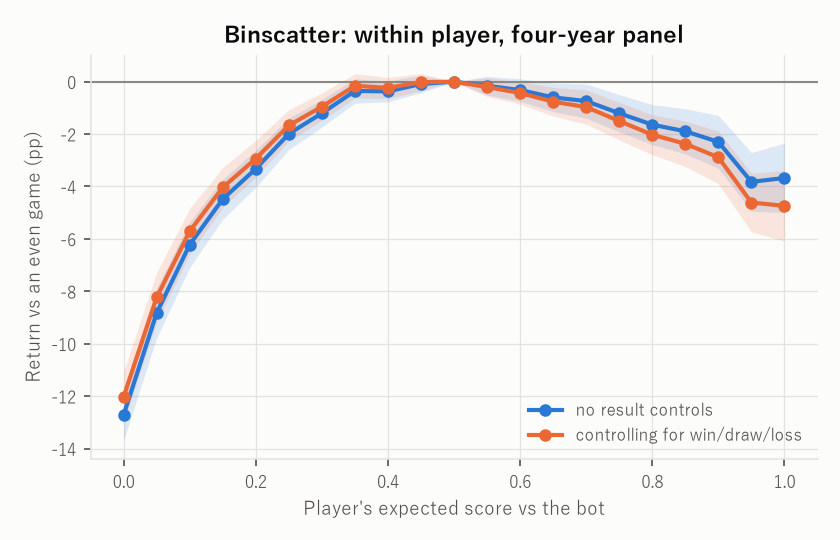

In [26]:
# figure 2: the Binscatter of the main model, with and without the result
fig, (ax_flex,) = new_figure(1, width=5.6, height=3.6)
flex = pd.DataFrame(flexible)
ax_flex.axhline(0, color=NEUTRAL, linewidth=1)
flex_series = (
    (False, "no result controls", SERIES[0]),
    (True, "controlling for win/draw/loss", SERIES[1]),
)
for with_result, name, color in flex_series:
    part = flex[(flex["with_result"] == with_result) & (flex["sessions"] >= 1000)]
    ax_flex.fill_between(
        part["es_mid"], 100 * part["ci_low"].fillna(0), 100 * part["ci_high"].fillna(0),
        color=color, alpha=0.15, lw=0,
    )
    ax_flex.plot(part["es_mid"], 100 * part["estimate"], color=color, marker="o", label=name)
ax_flex.set_xlabel("Player's expected score vs the bot")
ax_flex.set_ylabel("Return vs an even game (pp)")
ax_flex.set_title("Binscatter: within player, four-year panel")
ax_flex.legend()
display(Image(filename=save_figure(fig, FIGURE_DIR / "d1_binscatter.png")))

#### 10本のモデルに広げる

上の Binscatter を、次の10本のモデルのそれぞれに当てはめる。

- 2.3の9本のモデル：7・28・91日 × 同じボット（プレイヤー内、ペア内）とボットを問わない再訪（プレイヤー内）。どれも対局の結果を統制する。
- 結果を統制しない7日・同じボット・プレイヤー内のモデル（上の図の青い線）。

統制変数と比べ方（`within`）は、それぞれ2.3のモデルと同じである。基準は0.475〜0.525のビンで、各ビンの値は「互角の対局の後と比べて、再訪が何ポイント違うか」を表す。

#### 10本のコード

- 2.4の `find_spec()`、`spec_key()`、`spec_label()`、`control_terms()` で、モデル（`two_lines_specs()` の10本）を指定する。
- `model_sample()`：あるモデルが使うセッション（期間内の再訪が分かっているセッションの終わり。セッションが1つしかないプレイヤーや組を除く）を取り出し、レーティング差 `gap`（ボット − プレイヤー）を加える。
- `add_bins()`：ある列をビンに分ける（ビンは左端を含む）。
- `fit_binned()`：ビンのダミーのモデルを `fit_fe_lpm()` で当てはめ、ビンごとの値、95%区間、セッション数、ビンの es とレーティング差の平均、**ビンの係数どうしの共分散行列**を返す。共分散は、3.2以降でビンの値を組み合わせた検定（例えば2つのビンの差）に使う。
- `made_up_panel()`：答えの分かっている作りもののセッションを作る（以降の検査で使う）。

定義の後の検査では、作りものの階段状の曲線から、ビンの値が復元されることを確かめる。

In [27]:
def model_sample(panel: pl.DataFrame, spec: dict[str, Any]) -> pl.DataFrame:
    """The sessions a model uses, with the rating gap (bot minus player)."""
    kept = dict.fromkeys([spec["outcome"], *FRAME_COLUMNS, "gap", "player_score"])
    data = (
        panel.filter(pl.col(spec["flag"]) & pl.col(spec["outcome"]).is_not_null())
        .with_columns((pl.col("opponent_elo") - pl.col("player_elo")).alias("gap"))
        .select(*kept)
        .drop_nulls([spec["outcome"], *FRAME_COLUMNS])
    )
    # groups with one session carry no within-group information, as in fit_fe_lpm()
    return data.filter(pl.len().over(spec["within"]) > 1)


def add_bins(
    sample: pl.DataFrame, column: str, edges: tuple[float, ...], labels: tuple[str, ...]
) -> pl.DataFrame:
    """Adds `<column>_bin`, the label of the bin each row falls in (bins closed on the left)."""
    binned = pl.col(column).cut(list(edges), labels=list(labels), left_closed=True).cast(pl.Utf8)
    return sample.with_columns(binned.alias(f"{column}_bin"))


REFERENCE_ROW = {"estimate": 0.0, "std_err": 0.0, "ci_low": 0.0, "ci_high": 0.0, "p_value": None}


def fit_binned(
    sample: pl.DataFrame, spec: dict[str, Any], x: str, labels: tuple[str, ...], reference: str,
) -> dict[str, Any]:
    """Return per bin of `x` relative to the reference bin, with the bins' covariance.

    Args:
        sample: Rows of model_sample() with the bin labels in `<x>_bin` (from add_bins()).
        spec: The model whose controls and comparison (`within`) are used.
        x: The binned variable.
        labels: Bin labels in order; bins without sessions are left out.
        reference: The bin every other bin is compared with.
    """
    bin_column = f"{x}_bin"
    columns = dict.fromkeys([spec["outcome"], bin_column, *FRAME_COLUMNS])
    frame = to_model_frame(sample, list(columns))
    term = f"C({bin_column}, Treatment('{reference}'))"
    formula = f"{spec['outcome']} ~ {term} + {control_terms(spec)}"
    model = fit_fe_lpm(frame, formula, spec["within"], "player", spec_label(spec))
    prefix = f"{term}[T."
    estimated = {t[len(prefix) : -1]: t for t in model.terms["term"] if t.startswith(prefix)}
    shown = [label for label in labels if label in estimated or label == reference]
    names = [estimated.get(label) for label in shown]
    index = [i for i, name in enumerate(names) if name is not None]
    picked = [names[i] for i in index]
    cov = np.zeros((len(shown), len(shown)))
    cov[np.ix_(index, index)] = model.cov.loc[picked, picked].to_numpy()
    per_bin = sample.group_by(bin_column).agg(
        pl.len().alias("sessions"), pl.col(x).mean().alias("mean_x"),
        pl.col("es").mean().alias("mean_es"), pl.col("gap").mean().alias("mean_gap"),
    )
    counts = {row[bin_column]: row for row in per_bin.to_dicts()}
    bins = []
    for label, name in zip(shown, names, strict=True):
        values = REFERENCE_ROW if name is None else model.term(name)
        bins.append({
            "bin": label, **{key: values[key] for key in REFERENCE_ROW},
            **{key: counts[label][key] for key in ("sessions", "mean_x", "mean_es", "mean_gap")},
        })
    return {"n_obs": model.n_obs, "n_clusters": model.n_clusters, "bins": bins, "cov": cov.tolist()}


def gap_of_es(es: np.ndarray) -> np.ndarray:
    """The rating gap (bot minus player) that gives this expected score under Elo's formula."""
    return 400 * np.log10((1 - es) / es)


def made_up_panel(
    curve: Callable[[np.ndarray], np.ndarray], *, n_players: int = 300, n_sessions: int = 30,
    noise: float = 0.02, seed: int = 0,
) -> pl.DataFrame:
    """Made-up session ends whose returns are curve(es) plus a player level and noise."""
    rng = np.random.default_rng(seed)
    n = n_players * n_sessions
    player = np.repeat(np.arange(n_players), n_sessions)
    bot = rng.integers(0, 5, n)
    es = rng.uniform(0.01, 0.99, n)
    player_elo = rng.integers(1000, 2000, n)
    outcome = rng.choice(["win", "draw", "loss"], n)
    level = rng.normal(scale=0.1, size=n_players)[player]
    returns = {
        f"{kind}_{days}d": curve(es) + level + rng.normal(scale=noise, size=n)
        for kind in ("return", "any_return") for days in RETURN_WINDOWS_D
    }
    return pl.DataFrame({
        "player": [f"p{i}" for i in player], "opponent": [f"bot{b}" for b in bot],
        "pair": [f"p{i}|bot{b}" for i, b in zip(player, bot, strict=True)],
        "session_last": True, "player_session_last": True, **returns,
        "outcome": outcome,
        "player_score": np.select([outcome == "win", outcome == "draw"], [1.0, 0.5], 0.0),
        "es": es, "n_plies_100": rng.uniform(0.2, 1.5, n),
        "speed": rng.choice(list(ANALYSIS_SPEEDS), n), "player_elo": player_elo,
        "opponent_elo": player_elo + np.round(gap_of_es(es)).astype(int),
        "player_elo_c": (player_elo - 1500) / 100, "log_pair_idx": rng.uniform(0, 3, n),
        "month": rng.choice(["2024-01", "2024-02", "2024-03"], n),
    })


# check: a made-up step curve is recovered bin by bin, with the reference bin at zero
step = made_up_panel(lambda es: np.where(es < 0.45, -0.1, 0.0) - np.where(es > 0.8, 0.05, 0.0))
step_fit = fit_binned(
    add_bins(model_sample(step, MAIN_SPEC), "es", FLEX_EDGES, FLEX_LABELS),
    MAIN_SPEC, "es", FLEX_LABELS, FLEX_REFERENCE,
)
step_bins = {row["bin"]: row for row in step_fit["bins"]}
assert list(step_bins) == list(FLEX_LABELS)
assert abs(step_bins["0.200"]["estimate"] + 0.1) < 0.01
assert abs(step_bins["0.900"]["estimate"] + 0.05) < 0.01
assert step_bins[FLEX_REFERENCE]["estimate"] == 0.0
assert sum(row["sessions"] for row in step_fit["bins"]) == step_fit["n_obs"]
step_cov = np.array(step_fit["cov"])
assert np.allclose(step_cov, step_cov.T)
assert not step_cov[list(step_bins).index(FLEX_REFERENCE)].any()
print("checks passed")

checks passed


次のセルは10本の Binscatter を当てはめる（または保存済みの結果を読み込む）。続けて次を確かめる。

- 同じモデルは同じ数値を返す：主なモデルと結果を統制しないモデルの値は上の Binscatter の値と、各モデルのセッション数は2.3の `n_obs` と一致する（`assert`）。

表は、ビンごとの値（パーセントポイント）を10本のモデルについて並べたもの、その次の表はビンごとのセッション数である。列の名前は「同じボット（same）かボットを問わない（any）か、期間、比べ方」で、`(free)` は結果を統制しないモデルである。

In [28]:
def spec_short(spec: dict[str, Any]) -> str:
    """A column name for a model."""
    free = "" if spec["with_result"] else " (free)"
    return f"{spec['target'].split()[0]} {spec['days']}d {spec['within']}{free}"


def fit_es_bins(spec: dict[str, Any]) -> dict[str, Any]:
    """The Binscatter of one model."""
    sample = add_bins(model_sample(panel_games(), spec), "es", FLEX_EDGES, FLEX_LABELS)
    return fit_binned(sample, spec, "es", FLEX_LABELS, FLEX_REFERENCE)


ALL_SPECS = two_lines_specs()
flexible_fits = {
    spec_key(spec): cached(f"panel_flexible_{spec_key(spec)}", lambda spec=spec: fit_es_bins(spec))
    for spec in ALL_SPECS
}

# the same models give the same numbers as the Binscatter above and the models of 2.3
for spec in (MAIN_SPEC, FREE_SPEC):
    earlier = {
        r["es_bin"]: r["estimate"] for r in flexible if r["with_result"] == spec["with_result"]
    }
    for row in flexible_fits[spec_key(spec)]["bins"]:
        assert math.isclose(row["estimate"], earlier[row["bin"]], abs_tol=1e-9)
for spec in ALL_SPECS:
    if spec["with_result"]:
        same = next(
            r for r in horizons if all(r[k] == spec[k] for k in ("target", "days", "within"))
        )
        assert flexible_fits[spec_key(spec)]["n_obs"] == same["n_obs"]


def curve_table(field: str, scale: float) -> pl.DataFrame:
    """One column per model, one row per expected-score bin."""
    columns = {
        spec_short(spec): [scale * row[field] for row in flexible_fits[spec_key(spec)]["bins"]]
        for spec in ALL_SPECS
    }
    return pl.DataFrame({"es_bin": FLEX_LABELS, **columns})


display(Markdown("**Return vs an even game (pp), by expected-score bin**"))
display(curve_table("estimate", 100.0))
display(Markdown("**Sessions by expected-score bin**"))
curve_table("sessions", 1.0)

**Return vs an even game (pp), by expected-score bin**

es_bin,same 7d player (free),same 7d pair,same 7d player,any 7d player,same 28d pair,same 28d player,any 28d player,same 91d pair,same 91d player,any 91d player
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""0.000""",-12.719638,-6.86396,-12.030028,-3.598181,-5.819133,-13.631596,-3.222235,-5.537995,-14.93521,-2.859406
"""0.050""",-8.830851,-6.384149,-8.233736,-3.527837,-5.861651,-8.359477,-3.109106,-6.168548,-8.557095,-3.1971
"""0.100""",-6.219248,-5.372089,-5.708345,-3.031465,-4.882941,-5.449781,-2.824756,-4.977747,-5.448479,-2.934492
"""0.150""",-4.48353,-4.067546,-4.037868,-2.513604,-3.662365,-3.627776,-2.342321,-3.761758,-3.582443,-2.357738
"""0.200""",-3.32371,-3.44103,-2.938889,-2.078587,-2.86461,-2.376004,-1.602774,-2.821028,-2.126189,-1.619067
"""0.250""",-1.9904,-2.342191,-1.668793,-1.42435,-1.844683,-1.17159,-0.923118,-1.812749,-0.942728,-0.762516
"""0.300""",-1.205071,-1.542228,-0.953605,-0.844982,-1.278968,-0.690888,-0.684358,-1.323672,-0.602638,-0.580658
"""0.350""",-0.354713,-0.59967,-0.157158,-0.272439,-0.415912,0.031053,-0.144721,-0.523712,0.059115,-0.195988
"""0.400""",-0.370403,-0.525319,-0.237263,-0.273046,-0.24642,-0.004179,0.046886,-0.310673,0.028187,-0.036531


**Sessions by expected-score bin**

es_bin,same 7d player (free),same 7d pair,same 7d player,any 7d player,same 28d pair,same 28d player,any 28d player,same 91d pair,same 91d player,any 91d player
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""0.000""",61354.0,35475.0,61354.0,44121.0,34024.0,59164.0,42466.0,30771.0,53783.0,38624.0
"""0.050""",46092.0,34809.0,46092.0,36020.0,33505.0,44535.0,34780.0,29523.0,39639.0,30961.0
"""0.100""",42878.0,35453.0,42878.0,35043.0,34386.0,41610.0,34022.0,30679.0,37247.0,30509.0
"""0.150""",45085.0,38784.0,45085.0,37718.0,37549.0,43682.0,36533.0,33681.0,39295.0,32895.0
"""0.200""",48903.0,43143.0,48903.0,41601.0,41871.0,47470.0,40409.0,38082.0,43161.0,36880.0
"""0.250""",53435.0,48268.0,53435.0,46434.0,47052.0,52082.0,45300.0,43145.0,47697.0,41646.0
"""0.300""",60825.0,56109.0,60825.0,53878.0,54760.0,59347.0,52638.0,50570.0,54714.0,48706.0
"""0.350""",66960.0,62545.0,66960.0,60083.0,61150.0,65452.0,58792.0,56699.0,60630.0,54643.0
"""0.400""",71097.0,66672.0,71097.0,64029.0,65140.0,69442.0,62588.0,60462.0,64352.0,58246.0


#### 図の読み方

図「10本の Binscatter」：期間ごとに1枚（左から7・28・91日）。各図に、結果を統制した3本（同じボット・プレイヤー内、同じボット・ペア内、ボットを問わない・プレイヤー内）を、95%区間（帯）とともに描く。セッションが1,000未満のビンは省く。灰色の棒は、同じボット・プレイヤー内のモデルのビンごとのセッション数（es の分布）で、曲線のどの部分が多くのデータに支えられているかを示す（棒の高さは図の中での相対的な大きさ）。

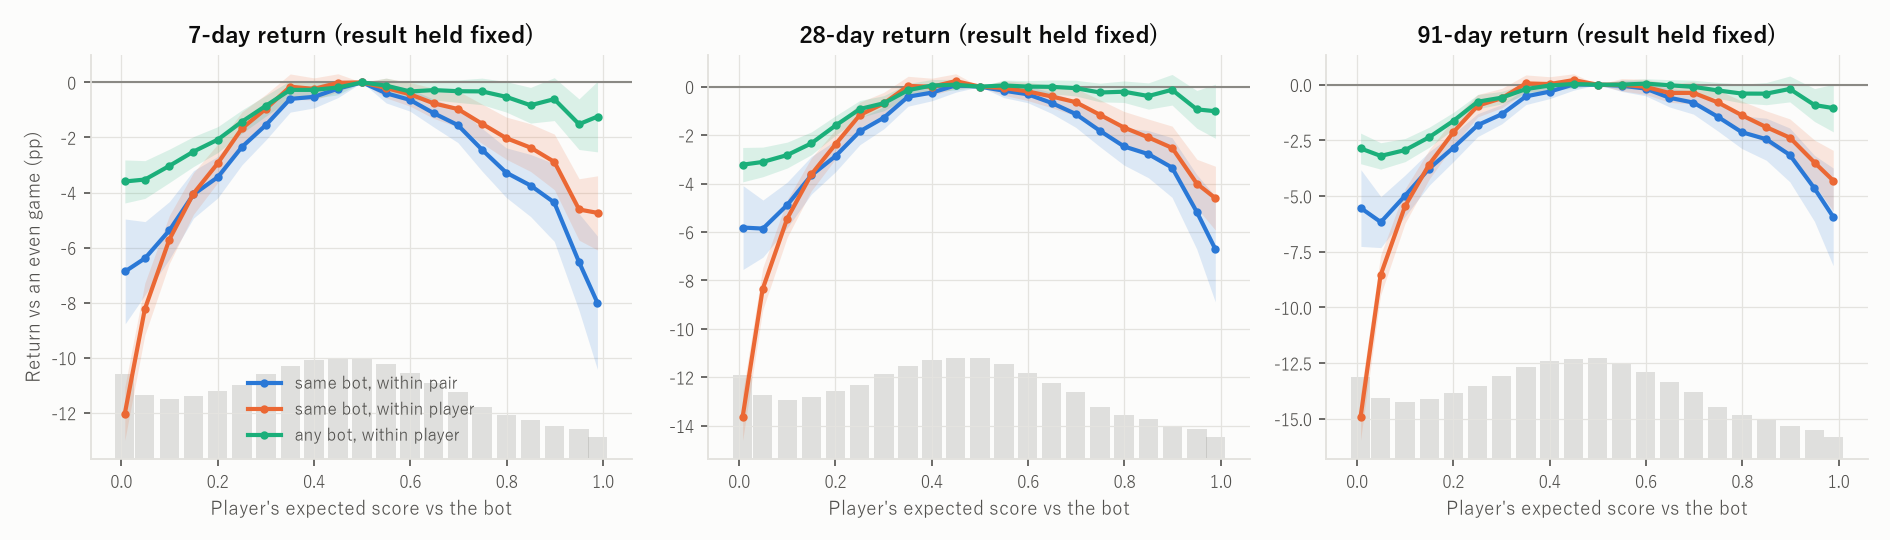

In [29]:
def plot_bins(ax: Any, bins: list[dict[str, Any]], x: str, color: str, label: str) -> None:
    """Draws a Binscatter (pp) with its 95% band, leaving out bins with under 1,000 sessions."""
    part = pd.DataFrame(bins)
    part = part[part["sessions"] >= MIN_RETURN_ROWS]
    ax.fill_between(
        part[x], 100 * part["ci_low"], 100 * part["ci_high"], color=color, alpha=0.15, lw=0
    )
    ax.plot(part[x], 100 * part["estimate"], color=color, marker="o", markersize=3, label=label)


def plot_support(ax: Any, bins: list[dict[str, Any]], x: str = "mean_x") -> None:
    """Draws the sessions per bin as grey bars along the bottom of the axes (a histogram of x)."""
    part = pd.DataFrame(bins)
    twin = ax.twinx()
    twin.bar(part[x], part["sessions"], width=0.04, color=NEUTRAL, alpha=0.25, lw=0)
    twin.set_ylim(0, 4 * part["sessions"].max())  # the tallest bar fills a quarter of the height
    twin.set_yticks([])
    twin.grid(False)
    ax.set_zorder(twin.get_zorder() + 1)  # the curve stays in front of the bars
    ax.patch.set_visible(False)


fig, axes = new_figure(3, width=4.2, height=3.6)
for ax, days in zip(axes, RETURN_WINDOWS_D, strict=True):
    ax.axhline(0, color=NEUTRAL, linewidth=1)
    shown = [s for s in ALL_SPECS if s["days"] == days and s["with_result"]]
    same_player = find_spec("same bot", days, "player", with_result=True)
    plot_support(ax, flexible_fits[spec_key(same_player)]["bins"])
    for spec, color in zip(shown, SERIES, strict=False):
        name = f"{spec['target']}, within {spec['within']}"
        plot_bins(ax, flexible_fits[spec_key(spec)]["bins"], "mean_x", color, name)
    ax.set_xlabel("Player's expected score vs the bot")
    ax.set_title(f"{days}-day return (result held fixed)")
axes[0].set_ylabel("Return vs an even game (pp)")
axes[0].legend()
display(Image(filename=save_figure(fig, FIGURE_DIR / "d1_flexible_all.png")))

#### 出力の読み方

- 10本すべてで、両側で下がる山の形になっている。
- プレイヤー内の同じボットへの再訪（7・28・91日、結果を統制）では、難しい側の端のビン（es 0〜0.025）で約12〜15ポイント、易しい側の端のビン（es 0.975〜1）で約4〜5ポイント下がり、難しい側の低下が大きい。
- ペア内では、両端の低下が近い大きさになる（7日で難しい側の端が約6.9ポイント、易しい側の端が約8.0ポイント）。プレイヤー内との違いが最も大きいのは、難しい側の端である。同じボットとの組の中で es が端まで動くことは少ないので、この差には es の動く幅の違いも関わりうる。この差が何から来るかは、このノートブックでは調べない。
- ボットを問わない再訪では、低下ははるかに小さい（難しい側の端で約3〜4ポイント、易しい側の端で約1ポイント）。

#### 図の読み方

図「期間と比べ方の比較」：同じ Binscatter を、比べる軸ごとに重ねた2枚の図。どれも結果を統制したモデルで、横軸はビンの中央である。モデルは「比べ方 + 期間（日）」で呼ぶ：Base は同じボットへの再訪（プレイヤー内）、PairFE は同じボットへの再訪（ペア内）、AnyBot はボットを問わない再訪（プレイヤー内）。

- 上：Base の7・28・91日（期間の違い）。
- 下：7日の Base・PairFE・AnyBot（比べ方の違い）。

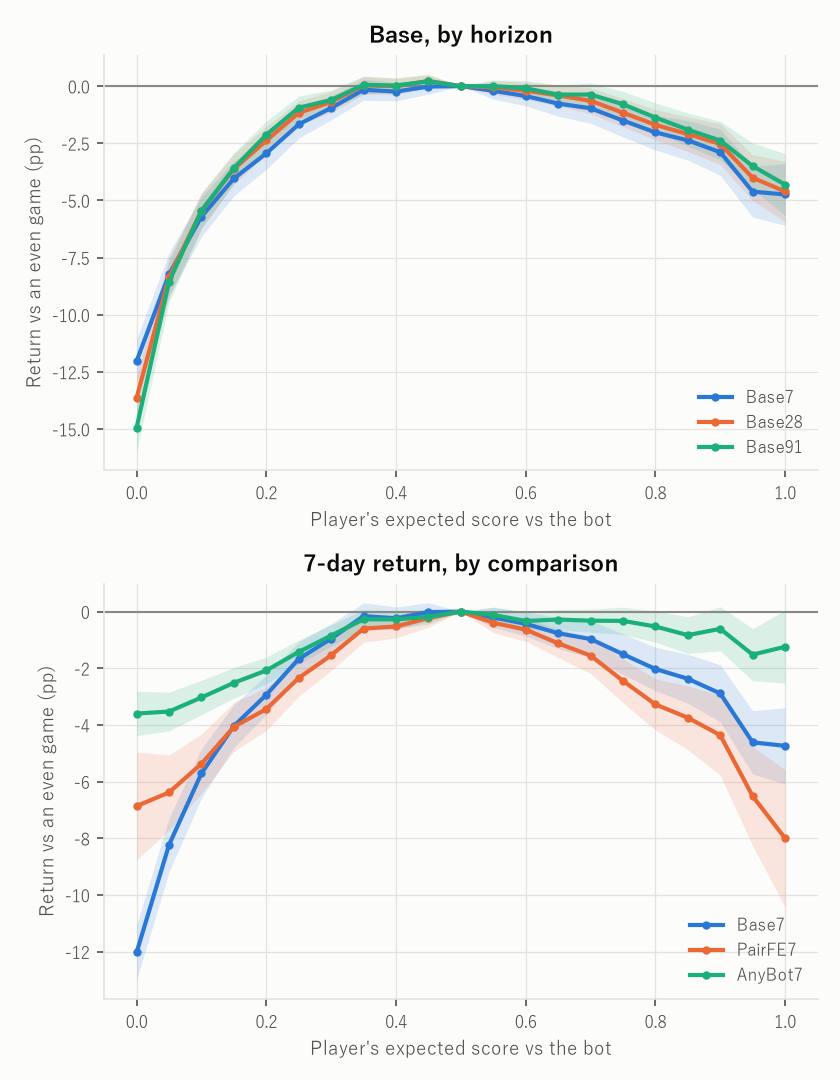

In [30]:
# figure 3: the Binscatter across horizons (left) and across comparisons (right)
MODEL_NAMES = {
    ("same bot", "player"): "Base", ("same bot", "pair"): "PairFE", ("any bot", "player"): "AnyBot",
}
overlays = (
    ("Base, by horizon", [find_spec("same bot", d, "player", with_result=True)
                          for d in RETURN_WINDOWS_D]),
    ("7-day return, by comparison", [find_spec(t, 7, w, with_result=True)
                                     for t, w in MODEL_NAMES]),
)
fig, axes = new_figure(1, width=5.6, height=3.6, n_rows=2)
for ax, (title, specs) in zip(axes, overlays, strict=True):
    ax.axhline(0, color=NEUTRAL, linewidth=1)
    for spec, color in zip(specs, SERIES, strict=False):
        fit = flexible_fits[spec_key(spec)]
        bins = [{**row, "es_mid": float(row["bin"])} for row in fit["bins"]]
        name = f"{MODEL_NAMES[(spec['target'], spec['within'])]}{spec['days']}"
        plot_bins(ax, bins, "es_mid", color, name)
    ax.set_xlabel("Player's expected score vs the bot")
    ax.set_ylabel("Return vs an even game (pp)")
    ax.set_title(title)
    ax.legend()
display(Image(filename=save_figure(fig, FIGURE_DIR / "d1_binscatter_models.png")))

### 3.2 非対称性：鏡像差の検定

#### 問い（Q3b）

互角（es = 0.5）から同じだけ離れたとき、ボットが強すぎる場合と弱すぎる場合とで、再訪の低下は同じか。

#### 方法

Binscatter の21のビンは、基準のビン（0.475〜0.525）を挟んで左右対称に並んでいる。基準を除く20のビンは、中央が0.5から同じだけ離れた10組になる（0.45 と 0.55、0.40 と 0.60、…、0 と 1。数字はビンの中央）。各組について、難しい側の値から易しい側の値を引いた**鏡像差**を求める。

- 鏡像差が負：難しい側の方が、再訪がより低い。
- 10組の差は、3.1で保存した係数とその共分散から、係数の線形結合として計算できる。その標準誤差も共分散から直接求まる（Wooldridge, 2010）。
- 検定は2つだけを、結果を見る前に決めておく（10組を1組ずつ検定すると、偶然の有意が混ざりやすい）。
  - 同時の Wald 検定（自由度10）：10組の差がすべて0か。Wald 検定は、推定値のベクトルがその共分散に照らして0からどれだけ離れているかを、カイ二乗分布で評価する。
  - 要約の1つの数：10組の差の平均と、その標準誤差。

#### この検定が答えること・答えないこと

- es は Elo の式で0.5を中心に対称なので、各組は「同じレーティング差だけ強いボットと弱いボット」の比較になる。この検定が答えるのは「同じ点差だけ強すぎる相手と弱すぎる相手のどちらの後に、より戻らなくなるか」である。
- 鏡像差は、頂点が0.5からずれていることと、左右の腕の傾きが違うことの両方を拾う。したがって「曲線の形が左右非対称だ」という意味の検定ではない。頂点から測った比較は、このノートブックでは行わない。
- 両端の組（0〜0.025 と 0.975〜1）は幅が半分で、レーティング差では上限のない開いたビンなので、実際のレーティング差の平均は左右で違う（下の表の `mean_gap`）。この組だけは厳密な鏡像ではない。

#### 両端の比

段階4で照合する `flexible_asymmetry`（難しい側の端のビンの値 ÷ 易しい側の端のビンの値）には、これまで信頼区間がなかった。ここでは、2つの推定値の比の95%区間を Fieller の方法（Fieller, 1954）で求める。Fieller の信頼区間は、比 r について「分子 − r × 分母」が0と有意に違わない r の範囲である。分母がはっきり0と違えば有限の信頼区間になる。

定義の後の検査では、次を確かめる。

- 対称な曲線では鏡像差が0になり、同時の Wald 検定が有意にならないこと。
- 作りもののデータで、既知の非対称（難しい側だけが下がる）が検出されること。
- 分母が確定しているときの Fieller の信頼区間が、通常の95%区間と一致すること。

In [31]:
ES_MIRROR_PAIRS = tuple(
    (f"{0.5 - 0.05 * k:.3f}", f"{0.5 + 0.05 * k:.3f}") for k in range(1, 11)
)  # (hard, easy) bins at the same distance from an even game, nearest first


def wald_test(values: np.ndarray, cov: np.ndarray) -> tuple[float, float]:
    """Wald statistic that every value is zero, and its chi-squared p-value."""
    statistic = float(values @ np.linalg.solve(cov, values))
    return statistic, float(stats.chi2.sf(statistic, values.size))


def linear_combination(
    estimates: np.ndarray, cov: np.ndarray, weights: np.ndarray
) -> dict[str, float]:
    """A weighted sum of estimates with its standard error, 95% interval and p-value."""
    value = float(weights @ estimates)
    se = math.sqrt(float(weights @ cov @ weights))
    p = float(2 * stats.norm.sf(abs(value) / se)) if se > 0 else math.nan
    return {"estimate": value, "std_err": se, "ci_low": value - Z95 * se,
            "ci_high": value + Z95 * se, "p_value": p}


def bin_arrays(fit: dict[str, Any]) -> tuple[list[str], np.ndarray, np.ndarray]:
    """The bin labels, estimates and covariance of a binned fit."""
    labels = [row["bin"] for row in fit["bins"]]
    return labels, np.array([row["estimate"] for row in fit["bins"]]), np.array(fit["cov"])


def mirror_test(
    fit: dict[str, Any], pairs: tuple[tuple[str, str], ...], min_sessions: int = MIN_RETURN_ROWS
) -> dict[str, Any]:
    """Hard-minus-easy differences of mirror bins: each pair, a joint Wald test, and their mean.

    Pairs with a bin of fewer than `min_sessions` sessions are left out.
    """
    labels, estimates, cov = bin_arrays(fit)
    sessions = {row["bin"]: row["sessions"] for row in fit["bins"]}
    kept = [
        (hard, easy) for hard, easy in pairs
        if min(sessions.get(hard, 0), sessions.get(easy, 0)) >= min_sessions
    ]
    contrast = np.zeros((len(kept), len(labels)))
    for row, (hard, easy) in enumerate(kept):
        contrast[row, labels.index(hard)], contrast[row, labels.index(easy)] = 1.0, -1.0
    differences, diff_cov = contrast @ estimates, contrast @ cov @ contrast.T
    statistic, p_value = wald_test(differences, diff_cov)
    mean = linear_combination(differences, diff_cov, np.full(len(kept), 1 / len(kept)))
    rows = [
        {"hard_bin": hard, "easy_bin": easy,
         **linear_combination(differences, diff_cov, np.eye(len(kept))[row])}
        for row, (hard, easy) in enumerate(kept)
    ]
    return {"pairs": rows, "n_pairs": len(kept), "wald": statistic, "p_value": p_value,
            **{f"mean_{key}": value for key, value in mean.items()}}


def fieller_interval(
    a: float, b: float, v_aa: float, v_ab: float, v_bb: float
) -> tuple[float, float]:
    """95% Fieller (1954) interval of the ratio a / b; (nan, nan) when it is unbounded."""
    z2 = Z95**2
    qa, qb, qc = b * b - z2 * v_bb, -2 * (a * b - z2 * v_ab), a * a - z2 * v_aa
    discriminant = qb * qb - 4 * qa * qc
    if qa <= 0 or discriminant < 0:
        return math.nan, math.nan
    root = math.sqrt(discriminant)
    return (-qb - root) / (2 * qa), (-qb + root) / (2 * qa)


def end_ratio(
    fit: dict[str, Any], hard: str = FLEX_LABELS[0], easy: str = FLEX_LABELS[-1]
) -> dict[str, float]:
    """The hardest bin's value over the easiest bin's value, with a Fieller interval."""
    labels, estimates, cov = bin_arrays(fit)
    i, j = labels.index(hard), labels.index(easy)
    low, high = fieller_interval(estimates[i], estimates[j], cov[i, i], cov[i, j], cov[j, j])
    return {"ratio": float(estimates[i] / estimates[j]), "ci_low": low, "ci_high": high}


def made_up_fit(estimates: dict[str, float], variance: float) -> dict[str, Any]:
    """A binned fit with chosen estimates and independent errors (reference bin exact)."""
    labels = list(estimates)
    cov = np.diag([0.0 if label == FLEX_REFERENCE else variance for label in labels])
    bins = [
        {"bin": label, "estimate": value, "sessions": 10**6} for label, value in estimates.items()
    ]
    return {"bins": bins, "cov": cov.tolist()}


# check 1: a symmetric curve has zero mirror differences
symmetric = made_up_fit({label: -abs(float(label) - 0.5) for label in FLEX_LABELS}, 1e-4)
test = mirror_test(symmetric, ES_MIRROR_PAIRS)
assert test["n_pairs"] == 10 and math.isclose(test["wald"], 0.0, abs_tol=1e-12)
assert math.isclose(test["mean_estimate"], 0.0, abs_tol=1e-12)
# pair (0.450, 0.550): two independent errors of variance 1e-4
assert math.isclose(test["pairs"][0]["std_err"], math.sqrt(2e-4))

# check 2: a made-up hard-side drop is detected, and none is found when there is none
for drop, detected in ((0.05, True), (0.0, False)):
    made_up_drop = made_up_panel(
        lambda es, d=drop: -d * (es < 0.3) - 0.03 * (np.abs(es - 0.5) > 0.3)
    )
    made_up_bins = add_bins(model_sample(made_up_drop, MAIN_SPEC), "es", FLEX_EDGES, FLEX_LABELS)
    fit = fit_binned(made_up_bins, MAIN_SPEC, "es", FLEX_LABELS, FLEX_REFERENCE)
    test = mirror_test(fit, ES_MIRROR_PAIRS, min_sessions=0)
    assert (test["p_value"] < ALPHA) == detected and (test["mean_estimate"] < -0.01) == detected

# check 3: with an exact denominator, Fieller's interval is a / b +- z se(a) / |b|
low, high = fieller_interval(-0.1, -0.04, 0.0001, 0.0, 0.0)
assert math.isclose(low, 2.5 - Z95 * 0.25) and math.isclose(high, 2.5 + Z95 * 0.25)
print("checks passed")

checks passed


次のセルは、10本のモデルの Binscatter に鏡像差の検定を当てはめる。

- 1つ目の表：モデルごとの要約。`n_pairs` は組の数（どちらのビンにも1,000以上のセッションがある組）、`wald` と `p_value` は同時の Wald 検定、`mean_estimate`〜`mean_p_value` は10組の差の平均とその標準誤差、95%区間、p 値（パーセントポイントでなく確率の単位）。`end_bins` は残った組のうち最も外側の組、`end_ratio` はその2つのビンの比（難しい側 ÷ 易しい側）、`end_ratio_ci_low`〜`end_ratio_ci_high` はその Fieller の95%区間。
- 2つ目の表：主なモデル（7日・同じボット・プレイヤー内、結果を統制）の組ごとの差。`distance` はビンの中央と0.5の距離である。

In [32]:
def mirror_row(fit: dict[str, Any], **labels: Any) -> dict[str, Any]:
    """The mirror test and the end ratio (outermost pair kept) of one fit, as one table row."""
    test = mirror_test(fit, ES_MIRROR_PAIRS)
    outermost = test["pairs"][-1]
    ratio = end_ratio(fit, outermost["hard_bin"], outermost["easy_bin"])
    return {
        **labels, "n_pairs": test["n_pairs"], "wald": test["wald"], "p_value": test["p_value"],
        **{key: value for key, value in test.items() if key.startswith("mean_")},
        "end_bins": f"{outermost['hard_bin']}/{outermost['easy_bin']}",
        "end_ratio": ratio["ratio"], "end_ratio_ci_low": ratio["ci_low"],
        "end_ratio_ci_high": ratio["ci_high"],
    }


def mirror_rows(
    fits: dict[str, dict[str, Any]], specs: list[dict[str, Any]], axis: str
) -> list[dict[str, Any]]:
    """mirror_row() of each model."""
    return [mirror_row(fits[spec_key(spec)], axis=axis, **spec_columns(spec)) for spec in specs]


mirror = mirror_rows(flexible_fits, ALL_SPECS, "es")
main_pairs = [
    {"distance": round(0.5 - float(row["hard_bin"]), 3), **row}
    for row in mirror_test(flexible_fits[spec_key(MAIN_SPEC)], ES_MIRROR_PAIRS)["pairs"]
]
display(pl.DataFrame(mirror))
pl.DataFrame(main_pairs)

axis,target,days,within,with_result,n_pairs,wald,p_value,mean_estimate,mean_std_err,mean_ci_low,mean_ci_high,mean_p_value,end_bins,end_ratio,end_ratio_ci_low,end_ratio_ci_high
str,str,i64,str,bool,i64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64
"""es""","""same bot""",7,"""player""",false,10,155.25293,3.0885e-28,-0.023233,0.003039,-0.029189,-0.017276,2.0929e-14,"""0.000/1.000""",3.460611,2.544127,5.383199
"""es""","""same bot""",7,"""pair""",true,10,9.370769,0.497314,0.000679,0.005135,-0.009384,0.010743,0.894722,"""0.000/1.000""",0.857975,0.551456,1.356617
"""es""","""same bot""",7,"""player""",true,10,103.474017,1.0968e-17,-0.015477,0.003039,-0.021433,-0.009522,3.5119e-7,"""0.000/1.000""",2.538922,1.971847,3.533066
"""es""","""any bot""",7,"""player""",true,10,46.71018,0.000001,-0.01165,0.002122,-0.01581,-0.00749,4.0399e-8,"""0.000/1.000""",2.898498,NaN,NaN
"""es""","""same bot""",28,"""pair""",true,10,11.606586,0.312249,-0.002244,0.004462,-0.010989,0.006502,0.615111,"""0.000/1.000""",0.86775,0.541339,1.417942
"""es""","""same bot""",28,"""player""",true,10,148.956338,6.1106e-27,-0.017659,0.002785,-0.023118,-0.012201,2.2841e-10,"""0.000/1.000""",2.959405,2.286213,4.15148
"""es""","""any bot""",28,"""player""",true,10,65.787444,2.8646e-10,-0.011788,0.0018,-0.015316,-0.00826,5.7834e-11,"""0.000/1.000""",3.172219,NaN,NaN
"""es""","""same bot""",91,"""pair""",true,10,14.500059,0.15138,-0.005868,0.004285,-0.014266,0.002531,0.170884,"""0.000/1.000""",0.933525,0.561974,1.623096
"""es""","""same bot""",91,"""player""",true,10,181.355775,1.2253e-33,-0.020819,0.002717,-0.026144,-0.015494,1.8221e-14,"""0.000/1.000""",3.469313,2.621569,5.073185


distance,hard_bin,easy_bin,estimate,std_err,ci_low,ci_high,p_value
f64,str,str,f64,f64,f64,f64,f64
0.05,"""0.450""","""0.550""",0.001869,0.002116,-0.002278,0.006016,0.376967
0.1,"""0.400""","""0.600""",0.001942,0.002706,-0.003361,0.007245,0.472844
0.15,"""0.350""","""0.650""",0.006068,0.003281,-0.000362,0.012499,0.064376
0.2,"""0.300""","""0.700""",0.000136,0.003787,-0.007285,0.007558,0.971253
0.25,"""0.250""","""0.750""",-0.00166,0.004296,-0.01008,0.006759,0.69911
0.3,"""0.200""","""0.800""",-0.009143,0.004842,-0.018633,0.000348,0.059
0.35,"""0.150""","""0.850""",-0.016678,0.005371,-0.027205,-0.006151,0.001901
0.4,"""0.100""","""0.900""",-0.028207,0.006214,-0.040387,-0.016027,0.000006
0.45,"""0.050""","""0.950""",-0.036184,0.006815,-0.049541,-0.022826,1.1007e-7


#### 図の読み方

図「互角を軸に折り返した曲線」：横軸はビンの中央と0.5の距離、縦軸は互角の対局の後と比べた再訪の違い（パーセントポイント）。難しい側（es < 0.5）と易しい側（es > 0.5）を重ねて描く。モデルは主なモデル、すなわち結果を統制した Base7（7日・同じボット・プレイヤー内）である。2本の線の間の縦の差が、鏡像差である。

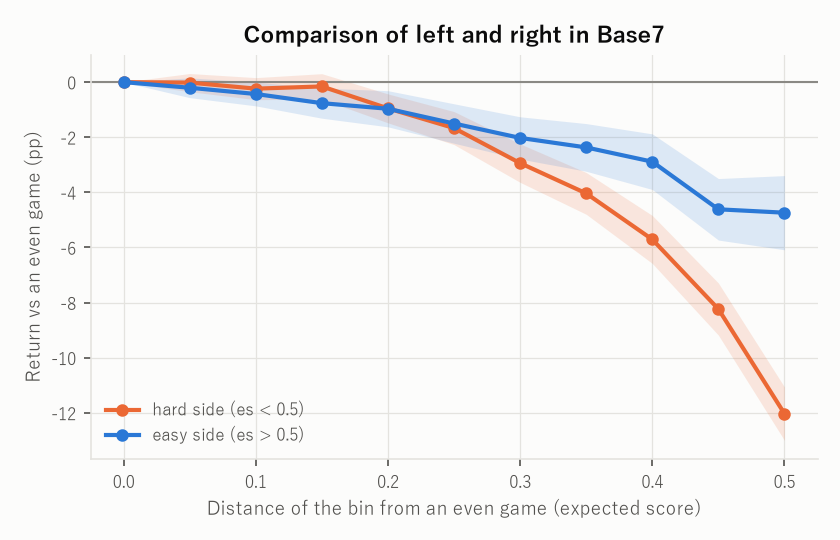

In [33]:
# figure 4: the Base7 Binscatter (result held fixed) folded at an even game
fig, (ax,) = new_figure(1, width=5.6, height=3.6)
bins = pd.DataFrame(flexible_fits[spec_key(MAIN_SPEC)]["bins"])
bins["distance"] = (bins["bin"].astype(float) - 0.5).abs()
ax.axhline(0, color=NEUTRAL, linewidth=1)
centre = bins["bin"].astype(float)  # the reference bin (distance 0) starts both sides
for side, chosen, color in (("hard side (es < 0.5)", centre <= 0.5, SERIES[1]),
                            ("easy side (es > 0.5)", centre >= 0.5, SERIES[0])):
    part = bins[chosen].sort_values("distance")
    ax.fill_between(part["distance"], 100 * part["ci_low"], 100 * part["ci_high"],
                    color=color, alpha=0.15, lw=0)
    ax.plot(part["distance"], 100 * part["estimate"], color=color, marker="o", label=side)
ax.set_xlabel("Distance of the bin from an even game (expected score)")
ax.set_ylabel("Return vs an even game (pp)")
ax.set_title("Comparison of left and right in Base7")
ax.legend()
display(Image(filename=save_figure(fig, FIGURE_DIR / "d1_mirror.png")))

#### 出力の読み方

- プレイヤー内のモデルでは、6本すべてで鏡像差の平均が負で、同時の Wald 検定も有意である（p < 10⁻⁵）。主なモデルでは、互角から同じだけ離れたとき、難しい側の再訪は易しい側より平均で約1.5ポイント（95%区間 1.0〜2.1）低い。結果を統制しないモデルでは約2.3ポイントである。
- 主なモデルの組ごとの差は、互角から0.3離れるまでは0と区別できず、それより外側で負に大きくなる（最も外側の組で約7.3ポイント）。
- 両端の比は、主なモデルで約2.5（Fieller の95%区間 2.0〜3.5）、結果を統制しないモデルで約3.5（2.5〜5.4）である。段階4で照合する `flexible_asymmetry` に、ここで初めて95%区間が付いた。
- ペア内のモデルでは、非対称性ははっきりしない（7日：鏡像差の平均はほぼ0、同時の検定 p ≈ 0.5、両端の比 ≈ 0.9）。「同じ点差だけ強すぎる相手の後のほうが戻らない」という非対称性は、主に、ボットを選び替えるセッションどうしの比較から来ている。ペア内では es の動く幅が狭いことも関わりうる。その点は、このノートブックでは調べない。

## 4. 論文のすべての数値の照合

### 問い

論文に書いたすべての数値を、このコードから再現できるか。

### 数値を集める

最初のセルは、段階2・3の結果を1つの辞書 `summary` にまとめ、次を書き出す。

- `summary`（`results/summary.json`）。段階3の結果は `summary["shape"]` にある。
- そのもとになる表（`results/*.csv`。段階3の表は `results/shape_*.csv`）

ここで、次の2つの数値を導く。

- 段階2の曲線の項の p 値のうち、最大のもの。
- 段階2のプレイヤー内の曲線で、es = 0.10 から頂点まで動いたときの、7日再訪の増分。

### 照合

`expected/paper_values.json` に、論文に書いたとおりの数値と、それが `summary` のどこにあるかを並べてある。
次のいずれかを満たせば、再現できたとみなす。

- 計算し直した値を同じ桁数に丸めた値が一致する（`kind` = `round`）。
- 論文に書いた上限を満たす（例えば「p < 0.001」。`kind` = `below`）。
- 論文に書いた下限に達する（例えば「有意でない」を p ≥ 0.05 とする場合。`kind` = `at_least`）。

### 出力の読み方

- 太字の行：再現できた数値の数。
- 最初の表：一致*しなかった*数値の一覧。空であるべきである。
- 2つ目の表：すべての数値の一覧。`results/comparison.csv` にも保存する。
  - `section`、`what`：どの箇所の何の数値か。
  - `paper`：論文の値。`reproduced`：計算し直した値。
  - `matches`：判定結果。`error`：計算できなかったときの理由。

In [34]:
week = next(
    r for r in horizons if (r["target"], r["days"], r["within"]) == ("same bot", 7, "player")
)
top = week["peak_es"]
any_week = next(
    r for r in horizons if (r["target"], r["days"], r["within"]) == ("any bot", 7, "player")
)


def flexible_bin(es_bin: str, with_result: bool) -> float:
    """The Binscatter's estimate in one bin."""
    return next(
        r["estimate"] for r in flexible if r["es_bin"] == es_bin and r["with_result"] == with_result
    )


def raw_drop_from_peak(bins: pl.DataFrame, min_sessions: int = 100) -> dict[str, float]:
    """Drop of the raw return rate from its highest bin to the hardest and the easiest bin."""
    shown = bins.filter(pl.col("n") >= min_sessions).sort("es_mid")
    rate = shown["rate"]
    return {"hard_end": float(rate.max() - rate[0]), "easy_end": float(rate.max() - rate[-1])}


summary = {
    "panel": {
        "describe": panel_size,
        "n_session_ends_7d": n_session_ends_7d,
        "horizons": horizons,
        "flexible": flexible,
        "two_lines": shape_tests,
        "two_lines_n_inverted_u": sum(
            r["u_shape"] and r["shape"] == "inverted U" for r in shape_tests if r["with_result"]
        ),
        # the ten two-lines tests, including the 7-day model without the result
        "two_lines_n_inverted_u_all": sum(
            r["u_shape"] and r["shape"] == "inverted U" for r in shape_tests
        ),
        "two_lines_max_p": max(max(r["slope_hard_p"], r["slope_easy_p"]) for r in shape_tests),
        # raw 7-day return (figure 1): drop from the highest bin to each end bin
        "raw_drop_from_peak": raw_drop_from_peak(binned),
        "horizons_max_p": max(max(r["es_p"], r["es2_p"]) for r in horizons),
        # 7-day return gained from es = 0.10 to the peak on the within-player curve
        "gain_beginner_to_peak": week["es"] * (top - 0.10) + week["es2"] * (top**2 - 0.10**2),
        # any-bot curvature as a share of the same-bot curvature (7 days, within player)
        "any_bot_curvature_share": any_week["es2"] / week["es2"],
        # drop in the hardest bin (es 0-0.025) over the drop in the easiest bin (es 0.975-1)
        "flexible_asymmetry": {
            name: flexible_bin(FLEX_LABELS[0], with_result)
            / flexible_bin(FLEX_LABELS[-1], with_result)
            for name, with_result in (("result_free", False), ("result_fixed", True))
        },
    },
}

# stage 3: the asymmetry of the curve
summary["shape"] = {
    "flexible": [
        {**spec_columns(spec), **row} for spec in ALL_SPECS
        for row in flexible_fits[spec_key(spec)]["bins"]
    ],
    "mirror": mirror,
    "mirror_pairs": main_pairs,
}

out_dir = config.RESULTS_DIR
binned.write_csv(out_dir / "return_by_es_bin.csv")
for key in ("horizons", "flexible", "two_lines"):
    pl.DataFrame(summary["panel"][key]).write_csv(out_dir / f"panel_{key}.csv")
for key, rows in summary["shape"].items():
    pl.DataFrame(rows, infer_schema_length=None).write_csv(out_dir / f"shape_{key}.csv")
(out_dir / "summary.json").write_text(
    json.dumps(summary, indent=2, default=json_default), encoding="utf-8", newline="\n"
)
print("written to", out_dir)

written to C:\Storage\Research\LichessAiPref\Individuals\Lichess_D1\results


In [35]:
def resolve(tree: dict[str, Any], path: str) -> Any:
    """Follows a dot path; `name[key=value,...]` picks the one list item whose fields match.

    A comma starts a new `key=value` only when an `=` follows it, so values may hold commas.
    """
    node: Any = tree
    # split on the dots outside brackets, so selector values may hold decimals
    for part in re.split(r"\.(?![^\[]*\])", path):
        name, _, selector = part.partition("[")
        node = node[name] if name else node
        if selector:
            fields = re.split(r",(?=[^,=]*=)", selector.rstrip("]"))
            wanted = dict(kv.split("=", 1) for kv in fields)
            matches = [item for item in node if all(str(item[k]) == v for k, v in wanted.items())]
            if len(matches) != 1:
                raise KeyError(f"{part}: {len(matches)} matches")
            node = matches[0]
    return node


def agrees(value: float, item: dict[str, Any]) -> bool:
    """Whether a recomputed value agrees with the printed one (see `kind` above)."""
    kind, printed = item.get("kind", "round"), float(item["paper"])
    if kind == "below":
        return value < printed
    if kind == "at_least":
        return value >= printed
    decimals = int(item["decimals"])
    return math.isclose(round(value, decimals), printed, abs_tol=10 ** -(decimals + 3))


def compare(tree: dict[str, Any], expected: dict[str, Any]) -> pl.DataFrame:
    """One row per printed number: printed value, recomputed value, and whether they agree."""
    rows = []
    for item in expected["values"]:
        row = {
            "section": item["section"], "what": item["what"], "paper": float(item["paper"]),
            "kind": item.get("kind", "round"),
        }
        try:
            value = float(resolve(tree, item["path"])) * float(item.get("scale", 1.0))
        except (KeyError, TypeError, ValueError) as exc:
            rows.append({**row, "reproduced": math.nan, "matches": False, "error": str(exc)})
            continue
        rows.append({**row, "reproduced": value, "matches": agrees(value, item), "error": ""})
    return pl.DataFrame(rows)


made_up = {"a": {"b": [{"days": 7, "x": 0.1234}, {"days": 28, "x": 9.0}]}}
assert resolve(made_up, "a.b[days=7].x") == 0.1234
assert resolve({"a": [{"bin": "0.025", "x": 1.0}]}, "a[bin=0.025].x") == 1.0
assert resolve({"a": [{"k": "p, q", "j": 1, "x": 2.0}]}, "a[k=p, q,j=1].x") == 2.0
assert compare(made_up, {"values": [
    {"section": "s", "what": "w", "path": "a.b[days=7].x", "paper": 0.12, "decimals": 2},
    {"section": "s", "what": "w", "path": "a.b[days=7].x", "paper": 0.1, "kind": "below"},
    {"section": "s", "what": "w", "path": "a.missing", "paper": 1.0, "decimals": 0},
]})["matches"].to_list() == [True, False, False]
print("checks passed")

checks passed


In [36]:
table = compare(summary, json.loads(config.EXPECTED_PATH.read_text(encoding="utf-8")))
table.write_csv(config.RESULTS_DIR / "comparison.csv")
n_matched = int(table["matches"].sum())
display(Markdown(f"**{n_matched} of {table.height} numbers in the paper reproduced.**"))
display(table.filter(~pl.col("matches")))
table

**336 of 336 numbers in the paper reproduced.**

section,what,paper,kind,reproduced,matches,error
str,str,f64,str,f64,bool,str


section,what,paper,kind,reproduced,matches,error
str,str,f64,str,f64,bool,str
"""data""","""analysable human-vs-bot games""",2.612524e6,"""round""",2.612524e6,true,""""""
"""data""","""players""",138408.0,"""round""",138408.0,true,""""""
"""data""","""bots""",4028.0,"""round""",4028.0,true,""""""
"""data""","""months""",49.0,"""round""",49.0,true,""""""
"""data""","""session ends, 7-day same-bot r…",1.031565e6,"""round""",1.031565e6,true,""""""
"""horizons""","""same bot 7 d, within player: e…",0.383,"""round""",0.382909,true,""""""
"""horizons""","""same bot 28 d, within player: …",0.41,"""round""",0.410151,true,""""""
"""horizons""","""same bot 91 d, within player: …",0.428,"""round""",0.427926,true,""""""
"""horizons""","""same bot 7 d, within player: e…",-0.35,"""round""",-0.350406,true,""""""


## 参考文献

本文中の（著者, 年）は、次の文献を指す。

- Angrist, J. D., & Pischke, J.-S. (2009). *Mostly Harmless Econometrics: An Empiricist's Companion*. Princeton University Press.
- Cameron, A. C., & Miller, D. L. (2015). A practitioner's guide to cluster-robust inference. *Journal of Human Resources*, 50(2), 317–372. https://doi.org/10.3368/jhr.50.2.317
- Cattaneo, M. D., Crump, R. K., Farrell, M. H., & Feng, Y. (2024). On binscatter. *American Economic Review*, 114(5), 1488–1514. https://doi.org/10.1257/aer.20221576
- Csikszentmihalyi, M. (1990). *Flow: The Psychology of Optimal Experience*. Harper & Row.
- Curran, P. J., & Bauer, D. J. (2011). The disaggregation of within-person and between-person effects in longitudinal models of change. *Annual Review of Psychology*, 62, 583–619. https://doi.org/10.1146/annurev.psych.093008.100356
- Deschênes, O., & Greenstone, M. (2011). Climate change, mortality, and adaptation: Evidence from annual fluctuations in weather in the US. *American Economic Journal: Applied Economics*, 3(4), 152–185. https://doi.org/10.1257/app.3.4.152
- Elo, A. E. (1978). *The Rating of Chessplayers, Past and Present*. Arco / Batsford.
- Fieller, E. C. (1954). Some problems in interval estimation. *Journal of the Royal Statistical Society: Series B*, 16(2), 175–185. https://doi.org/10.1111/j.2517-6161.1954.tb00159.x
- Glickman, M. E. (2022). *Example of the Glicko-2 system*（2022年3月22日版）. http://www.glicko.net/glicko/glicko2.pdf
- Haans, R. F. J., Pieters, C., & He, Z.-L. (2016). Thinking about U: Theorizing and testing U- and inverted U-shaped relationships in strategy research. *Strategic Management Journal*, 37(7), 1177–1195. https://doi.org/10.1002/smj.2399
- Ito, R.（伊藤 黎） (2026). AI対戦相手の難易度と再訪：オンラインチェス内のプレイヤー再訪行動の縦断的分析. 人工知能学会研究会資料.
- James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning: With Applications in R* (2nd ed.). Springer. https://doi.org/10.1007/978-1-0716-1418-1
- Lind, J. T., & Mehlum, H. (2010). With or without U? The appropriate test for a U-shaped relationship. *Oxford Bulletin of Economics and Statistics*, 72(1), 109–118. https://doi.org/10.1111/j.1468-0084.2009.00569.x
- Oehlert, G. W. (1992). A note on the delta method. *The American Statistician*, 46(1), 27–29. https://doi.org/10.1080/00031305.1992.10475842
- Royston, P., Altman, D. G., & Sauerbrei, W. (2006). Dichotomizing continuous predictors in multiple regression: A bad idea. *Statistics in Medicine*, 25(1), 127–141. https://doi.org/10.1002/sim.2331
- Simonsohn, U. (2018). Two lines: A valid alternative to the invalid testing of U-shaped relationships with quadratic regressions. *Advances in Methods and Practices in Psychological Science*, 1(4), 538–555. https://doi.org/10.1177/2515245918805755
- Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association*, 22(158), 209–212. https://doi.org/10.1080/01621459.1927.10502953
- Wood, S. N. (2017). *Generalized Additive Models: An Introduction with R* (2nd ed.). Chapman & Hall/CRC. https://doi.org/10.1201/9781315370279
- Wooldridge, J. M. (2010). *Econometric Analysis of Cross Section and Panel Data* (2nd ed.). MIT Press.